#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler

#### Load Dataset

In [ ]:
file_path = "../data/RTA Data 2020 to July 2023.xlsx"
df = pd.read_excel(file_path)

#### Visualize Dataset

In [3]:
df.head()

,EcYear,EcNumber,CallTime,EmergencyArea,TotalPatientsInEmergency,Gender,Age,HospitalName,Reason,responsetime,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,2020,31486,2020-12-31 22:41:47,NEAR APS SCHOOL FORT ROAD RWP,1,Male,27.0,BBH,Bike Slip,10.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2020,31485,2020-12-31 22:25:00,"Infront of Daig.com, Near Dha gate 2, gt road...",1,Male,20.0,NaN,Car hit Footpath,12.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2020,31483,2020-12-31 21:54:59,Muhammadi chowk arshad bakery khyaban e sirsye...,1,Male,48.0,BBH,Rickshaw hit with Car,10.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,2020,31482,2020-12-31 21:24:22,"Gulzar e quaid, T/W Katcheri Near Attock Pump,...",1,Male,45.0,NaN,Car hit Car and runaway,5.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2020,31479,2020-12-31 21:03:49,Taaj Company Gawalmandi Chowk Liaqat Baag Road...,1,Male,22.0,NaN,Unknown Bike hit Bike and runaway,5.0,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.tail()

,EcYear,EcNumber,CallTime,EmergencyArea,TotalPatientsInEmergency,Gender,Age,HospitalName,Reason,responsetime,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
46184,2023,NaN,NaT,Infront Of Mian G hotel GT Road Mandra,2,Male,20.0,"RHC,Mandra,Rawalpindi",.,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
46185,2023,356986,2023-01-01 04:23:00,"Barma Shell Depu Dhoke Munshi Road, Fazal Town...",1,Male,16.0,DHQ,Bike slipped due to over speed.(RIN.6276) C D...,11.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
46186,2023,356981,2023-01-01 02:16:00,Main Bakra Mandi Chowk Rwp,1,Female,10.0,NaN,RLF-2193 coure and ICT-593 corolla car colliped,1.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
46187,2023,356980,2023-01-01 02:02:00,"Darbar Adda, Mandi Morr, Bus Stop, Ijp Road, Rwp",1,Male,19.0,NaN,Bike slipped due to Over speed ( Bike no TSH ...,12.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
46188,2023,356977,2023-01-01 01:00:00,Near Rehmanabad Metro Station T/W Faizabad Mur...,1,Male,31.0,NaN,Both car hited eachother overspeed,2.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df.shape

(46189, 25)

In [6]:
df.columns

Index(['EcYear', 'EcNumber', 'CallTime', 'EmergencyArea',
       'TotalPatientsInEmergency', 'Gender', 'Age', 'HospitalName', 'Reason',
       'responsetime', 'EducationTitle', 'InjuryType', 'Cause',
       'PatientStatus', 'BicycleInvovled', 'BikesInvolved', 'BusesInvolved',
       'CarsInvolved', 'CartInvovled', 'RickshawsInvolved', 'TractorInvovled',
       'TrainsInvovled', 'TrucksInvolved', 'VansInvolved', 'OthersInvolved'],
      dtype='object')

In [7]:
df.describe()

,CallTime,Age,responsetime,BicycleInvovled,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
count,40233,46188.000000,46184.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000,46187.000000
mean,2021-11-23 18:43:21.099967744,32.447129,6.256106,0.008725,0.967242,0.009202,0.234049,0.001970,0.087297,0.009830,0.002208,0.044948,0.117392,0.009656
min,1900-01-02 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2021-01-03 12:01:47,21.000000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2021-12-01 09:01:00,29.000000,5.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2022-11-03 20:15:00,42.000000,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2023-07-31 17:11:00,118.000000,101.000000,2.000000,10.000000,2.000000,5.000000,1.000000,2.000000,1.000000,1.000000,3.000000,4.000000,2.000000
std,NaN,15.176229,4.901342,0.093467,0.578776,0.100349,0.448054,0.044344,0.289319,0.098657,0.046942,0.220947,0.334686,0.098893


#### Handling Null Values

In [8]:
df.isnull()   

,EcYear,EcNumber,CallTime,EmergencyArea,TotalPatientsInEmergency,Gender,Age,HospitalName,Reason,responsetime,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46184,False,True,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
46185,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
46186,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
46187,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


In [9]:
df.isnull().sum()

EcYear                          0
EcNumber                     7211
CallTime                     5956
EmergencyArea                   1
TotalPatientsInEmergency        0
Gender                          1
Age                             1
HospitalName                21950
Reason                          1
responsetime                    5
EducationTitle                  1
InjuryType                      2
Cause                           2
PatientStatus                   2
BicycleInvovled                 2
BikesInvolved                   2
BusesInvolved                   2
CarsInvolved                    2
CartInvovled                    2
RickshawsInvolved               2
TractorInvovled                 2
TrainsInvovled                  2
TrucksInvolved                  2
VansInvolved                    2
OthersInvolved                  2
dtype: int64

In [10]:
columns_to_drop = ['EcNumber', 'CallTime', 'HospitalName']
df.drop(columns=columns_to_drop, inplace=True)

In [11]:
df.head(10)

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,InjuryType,Cause,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,2020,NEAR APS SCHOOL FORT ROAD RWP,1,Male,27.0,Bike Slip,10.0,Intermediate,Minor,Over Speed,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2020,"Infront of Daig.com, Near Dha gate 2, gt road...",1,Male,20.0,Car hit Footpath,12.0,Illetrate,Minor,Over Speed,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2020,Muhammadi chowk arshad bakery khyaban e sirsye...,1,Male,48.0,Rickshaw hit with Car,10.0,Illetrate,Single Fracture,Over Speed,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,2020,"Gulzar e quaid, T/W Katcheri Near Attock Pump,...",1,Male,45.0,Car hit Car and runaway,5.0,Matric,Minor,Over Speed,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2020,Taaj Company Gawalmandi Chowk Liaqat Baag Road...,1,Male,22.0,Unknown Bike hit Bike and runaway,5.0,Matric,Single Fracture,Over Speed,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2020,Chour chowk under bridge towards saddar peshaw...,1,Male,50.0,Bike hit Bike and runaway,6.0,Matric,Minor,Over Speed,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,2020,Infront of Zam Zam CNG tipu road rwp,1,Male,18.0,Bike Slip,5.0,Matric,Head Injury,Over Speed,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,2020,Commite chowk pehlwan raveri murree road t.w f...,1,Male,25.0,"Fall from bike, where patient tak lift from bi...",4.0,Primary,Single Fracture,Carelessness,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,2020,Near Saint marys school gate Mazhar Qayoom roa...,1,Male,18.0,Bike Slip due to Oil on Road,4.0,Matric,Single Fracture,Carelessness,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2020,Infront of rasheed sweets kamran market kashmi...,1,Male,19.0,Rickshaw hit Pedestrian and runaway,3.0,Matric,Minor,Carelessness,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [12]:
df.isnull().sum().sum()

np.int64(38)

In [13]:
df.shape

(46189, 22)

In [14]:
df.dropna(inplace=True)

In [15]:
df.shape

(46182, 22)

In [16]:
df.isnull().sum()

EcYear                      0
EmergencyArea               0
TotalPatientsInEmergency    0
Gender                      0
Age                         0
Reason                      0
responsetime                0
EducationTitle              0
InjuryType                  0
Cause                       0
PatientStatus               0
BicycleInvovled             0
BikesInvolved               0
BusesInvolved               0
CarsInvolved                0
CartInvovled                0
RickshawsInvolved           0
TractorInvovled             0
TrainsInvovled              0
TrucksInvolved              0
VansInvolved                0
OthersInvolved              0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(0)

#### Removing Duplicates

In [18]:
df[df.duplicated()]

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,InjuryType,Cause,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
745,2020,Near sehal village chakri road Rwp,4,Male,42.0,same,8.0,Matric,Minor,Carelessness,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1546,2020,Infront of ashraf marriage hall dhoke hafiz ...,3,Male,16.0,same,3.0,Matric,Minor,Over Speed,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6037,2020,Near flying Club Old airport road rwp,3,Male,18.0,Same,7.0,Primary,Minor,Over Speed,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8301,2020,Main Ali Nawaz Chowk Khatarnaak More Rawal Roa...,5,Male,17.0,same,7.0,Matric,Minor,Over Speed,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9573,2020,Infront Of BAwali Hotel T/W Mandra GT Road Guj...,4,Male,50.0,same,6.0,Primary,Minor,U Turn,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
11314,2020,"Dhoke Muqadam Stop, Near Attock Pump/ LRBT, G ...",5,Female,45.0,Same,7.0,Middle,Minor,Over Speed,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
12518,2021,ranial near ranial choki chakri road rwp,4,Male,27.0,Same,8.0,Illetrate,Minor,Over Speed,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
17488,2021,"NEAR BRIDGE,BHARIATOWN PHASE 1,NEAR SIFFARI VI...",3,Male,18.0,Same,12.0,Primary,Minor,Carelessness,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21791,2021,Missa Kaswal GT Road Gujjar Khan Rwp,8,Male,30.0,same,10.0,Illetrate,Minor,Over Speed,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
23862,2021,AZAD PATTAN AZAD KASHMIR KAHUTA,5,Male,40.0,same,53.0,Illetrate,Head Injury,Over Speed,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [19]:
df.shape

(46182, 22)

In [20]:
df.drop_duplicates(inplace=True)

In [21]:
df.shape

(46154, 22)

In [22]:
df[df.duplicated()]

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,InjuryType,Cause,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved


#### Handling Outliers

<Axes: xlabel='Age'>

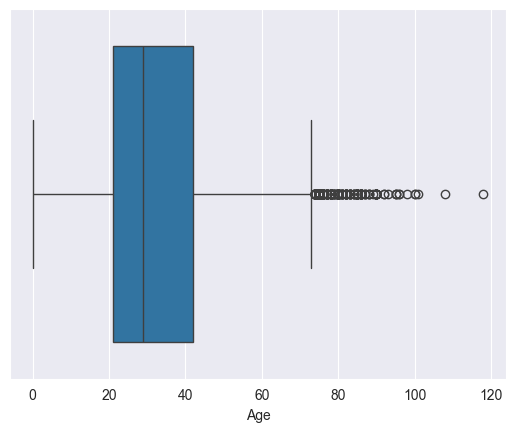

In [23]:
sns.boxplot(x=df['Age'])

<Axes: xlabel='responsetime'>

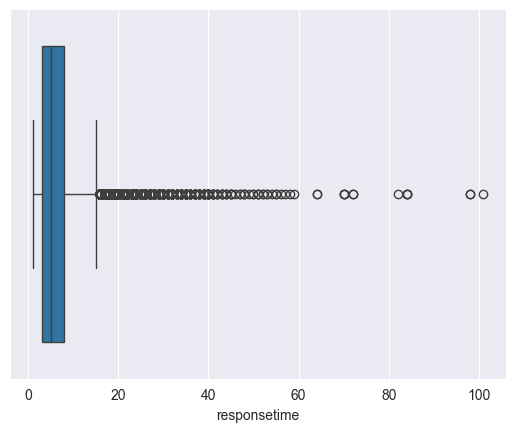

In [24]:
sns.boxplot(x=df['responsetime'])

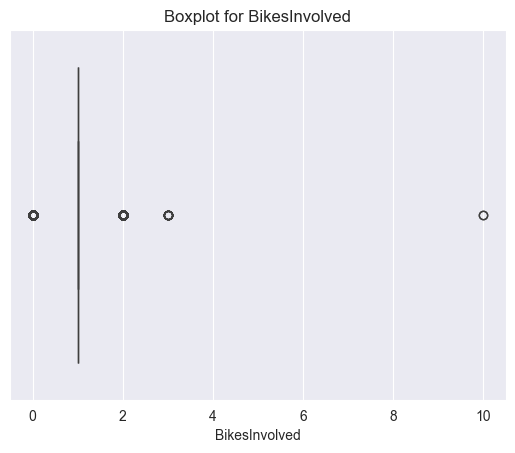

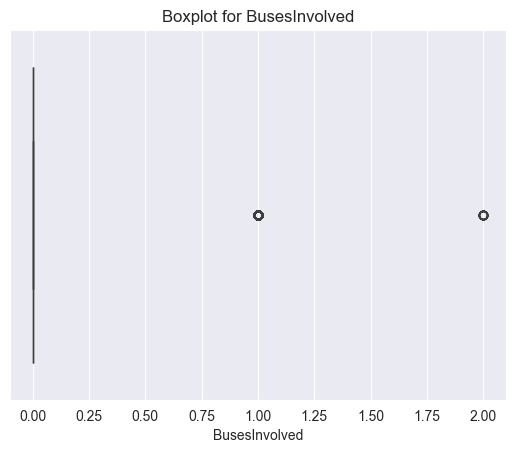

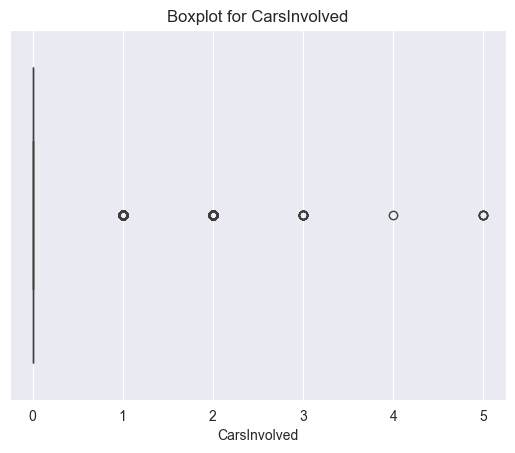

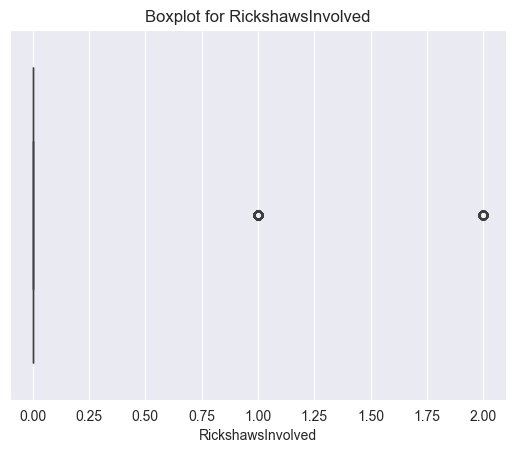

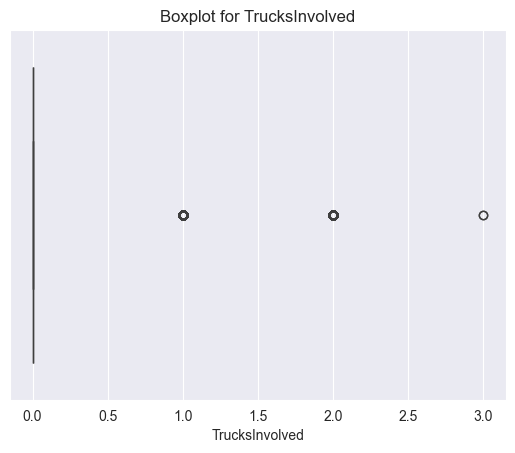

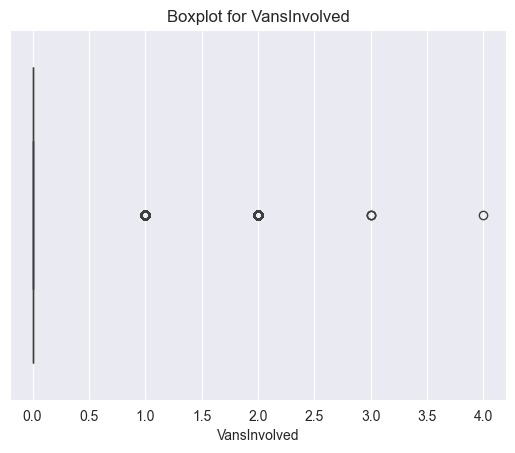

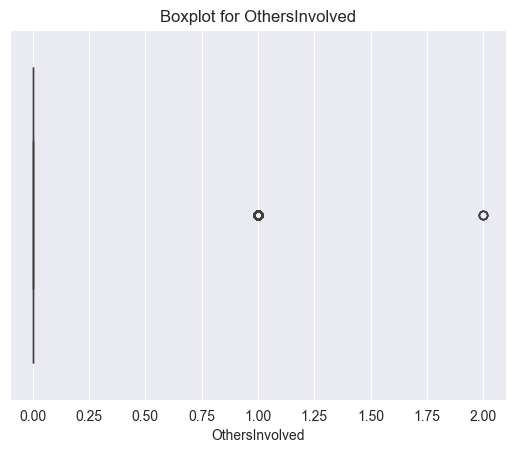

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

for x in df.columns:
    if "Involved" in x:
        sns.boxplot(x=df[x])
        plt.title(f"Boxplot for {x}")
        plt.show()


In [26]:
numerical_cols = ['Age', 'responsetime'] + [col for col in df.columns if 'Involved' in col]
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

<Axes: xlabel='Age'>

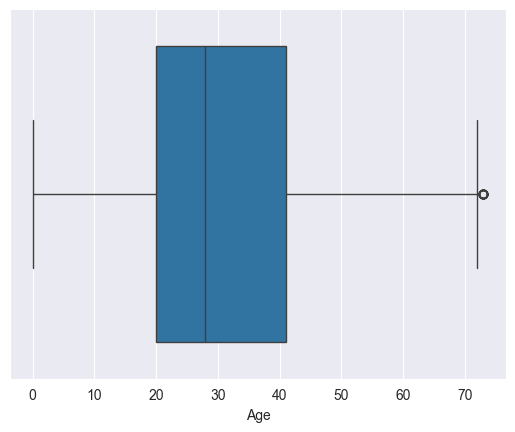

In [27]:
sns.boxplot(x=df['Age'])

<Axes: xlabel='responsetime'>

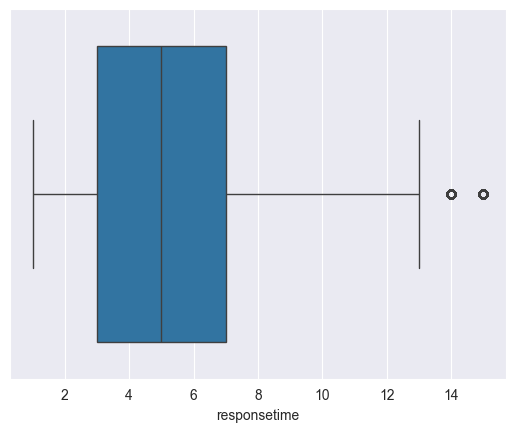

In [28]:
sns.boxplot(x=df['responsetime'])

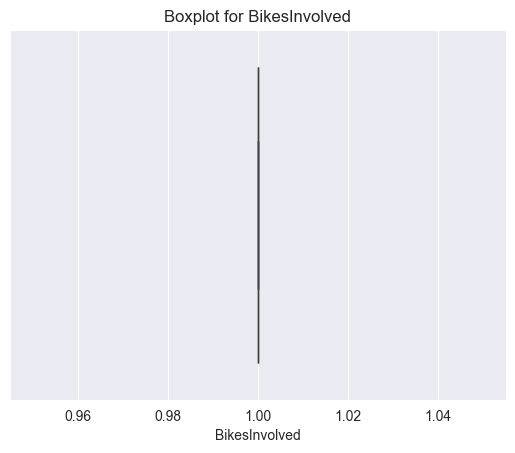

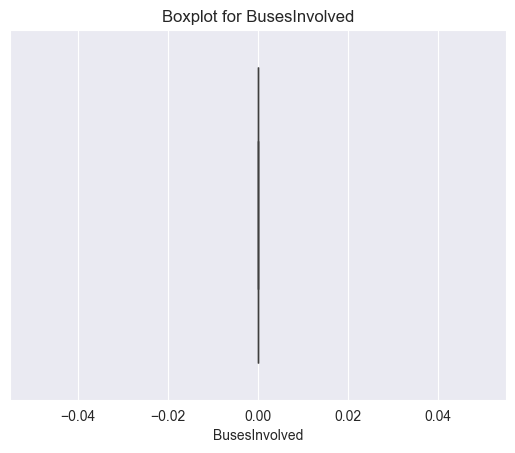

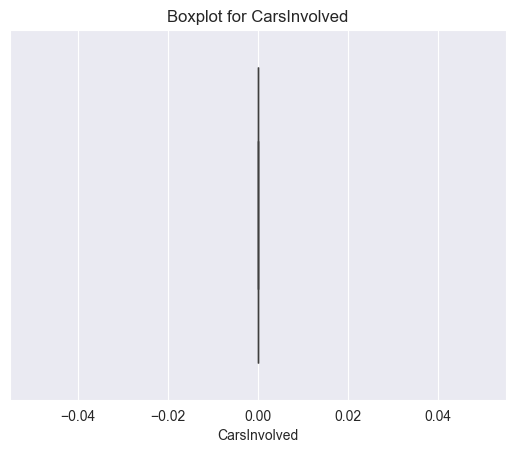

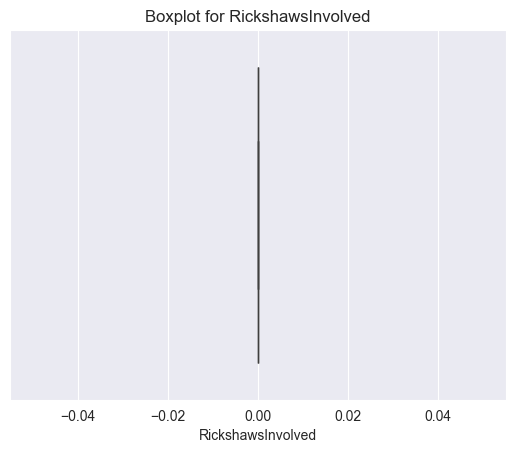

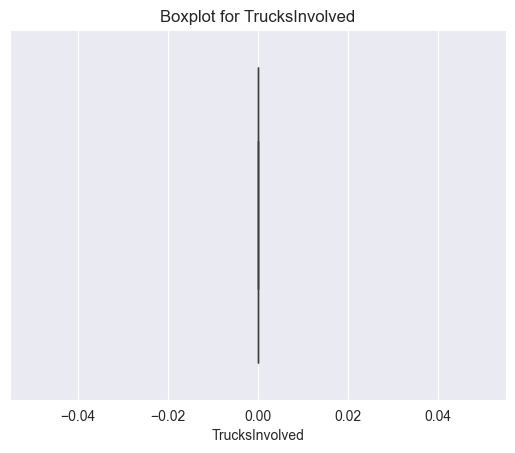

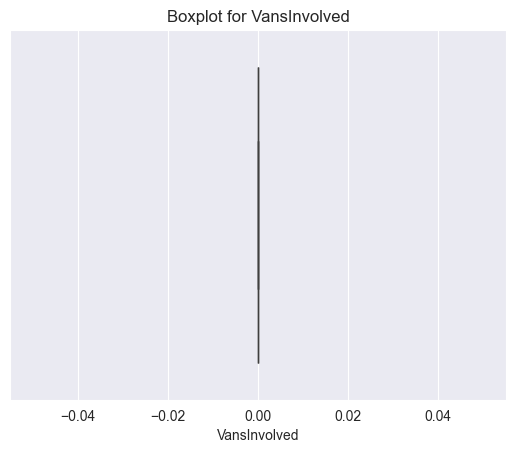

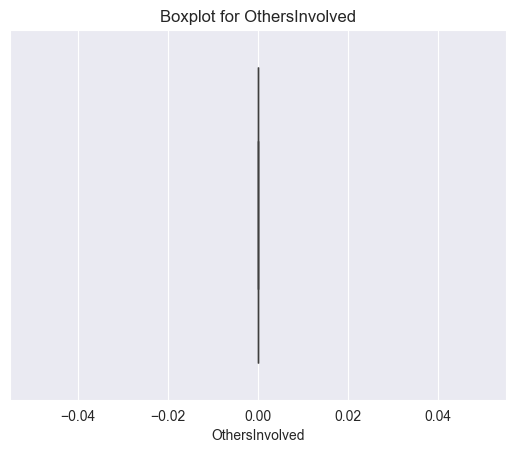

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

for x in df.columns:
    if "Involved" in x:
        sns.boxplot(x=df[x])
        plt.title(f"Boxplot for {x}")
        plt.show()


In [30]:
df.columns

Index(['EcYear', 'EmergencyArea', 'TotalPatientsInEmergency', 'Gender', 'Age',
       'Reason', 'responsetime', 'EducationTitle', 'InjuryType', 'Cause',
       'PatientStatus', 'BicycleInvovled', 'BikesInvolved', 'BusesInvolved',
       'CarsInvolved', 'CartInvovled', 'RickshawsInvolved', 'TractorInvovled',
       'TrainsInvovled', 'TrucksInvolved', 'VansInvolved', 'OthersInvolved'],
      dtype='object')

In [31]:
df.head()

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,InjuryType,Cause,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,2020,NEAR APS SCHOOL FORT ROAD RWP,1,Male,27.0,Bike Slip,10.0,Intermediate,Minor,Over Speed,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,2020,Infront of Zam Zam CNG tipu road rwp,1,Male,18.0,Bike Slip,5.0,Matric,Head Injury,Over Speed,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,2020,Commite chowk pehlwan raveri murree road t.w f...,1,Male,25.0,"Fall from bike, where patient tak lift from bi...",4.0,Primary,Single Fracture,Carelessness,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,2020,Near Saint marys school gate Mazhar Qayoom roa...,1,Male,18.0,Bike Slip due to Oil on Road,4.0,Matric,Single Fracture,Carelessness,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,2020,Infront of central station t.w chandni chowk rwp,1,Male,51.0,bike hit Pedetrian and runaway,2.0,Primary,Minor,Carelessness,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Define categorical and numerical columns

In [32]:
categorical_cols = [col for col in df.columns if df[col].dtype == 'object']
target_col = 'InjuryType'
categorical_cols.remove(target_col)

#### Label Encoding for Categorical Features

In [33]:
label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = label_encoder.fit_transform(df[col].astype(str))

In [34]:
df.head()

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,InjuryType,Cause,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,0,10383,0,1,27.0,5071,10.0,2,Minor,3,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0,7583,0,1,18.0,5071,5.0,4,Head Injury,3,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0,5512,0,1,25.0,7519,4.0,7,Single Fracture,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,11661,0,1,18.0,5116,4.0,4,Single Fracture,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,0,8155,0,1,51.0,8415,2.0,7,Minor,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [35]:
df.shape

(17815, 22)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17815 entries, 0 to 46187
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EcYear                    17815 non-null  int64  
 1   EmergencyArea             17815 non-null  int64  
 2   TotalPatientsInEmergency  17815 non-null  int64  
 3   Gender                    17815 non-null  int64  
 4   Age                       17815 non-null  float64
 5   Reason                    17815 non-null  int64  
 6   responsetime              17815 non-null  float64
 7   EducationTitle            17815 non-null  int64  
 8   InjuryType                17815 non-null  object 
 9   Cause                     17815 non-null  int64  
 10  PatientStatus             17815 non-null  int64  
 11  BicycleInvovled           17815 non-null  float64
 12  BikesInvolved             17815 non-null  float64
 13  BusesInvolved             17815 non-null  float64
 14  CarsInvolve

#### Split data into features and target

In [37]:
X = df.drop(columns=[target_col])
y = df[target_col]

In [38]:
X.head()

,EcYear,EmergencyArea,TotalPatientsInEmergency,Gender,Age,Reason,responsetime,EducationTitle,Cause,PatientStatus,...,BikesInvolved,BusesInvolved,CarsInvolved,CartInvovled,RickshawsInvolved,TractorInvovled,TrainsInvovled,TrucksInvolved,VansInvolved,OthersInvolved
0,0,10383,0,1,27.0,5071,10.0,2,3,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0,7583,0,1,18.0,5071,5.0,4,3,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0,5512,0,1,25.0,7519,4.0,7,0,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,11661,0,1,18.0,5116,4.0,4,0,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,0,8155,0,1,51.0,8415,2.0,7,0,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
X.columns

Index(['EcYear', 'EmergencyArea', 'TotalPatientsInEmergency', 'Gender', 'Age',
       'Reason', 'responsetime', 'EducationTitle', 'Cause', 'PatientStatus',
       'BicycleInvovled', 'BikesInvolved', 'BusesInvolved', 'CarsInvolved',
       'CartInvovled', 'RickshawsInvolved', 'TractorInvovled',
       'TrainsInvovled', 'TrucksInvolved', 'VansInvolved', 'OthersInvolved'],
      dtype='object')

In [40]:
y

0                  Minor
6            Head Injury
7        Single Fracture
8        Single Fracture
14                 Minor
              ...       
46171              Minor
46172        Head Injury
46179              Minor
46185              Minor
46187              Minor
Name: InjuryType, Length: 17815, dtype: object

#### Encode target variable

In [41]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

#### Store original labels for later use

In [42]:
label_mapping = dict(zip(le.classes_, range(len(le.classes_))))
inverse_mapping = dict(zip(range(len(le.classes_)), le.classes_))

#### Splitting the dataset into Train and Test in a 80:20 ratio.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

#### Define scalers and models with their parameters

In [44]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

#### Define Hyperparameters

In [45]:
dt_depths = [4, 5, 6, 7, 8, 9]
rf_estimators = [10, 50, 100, 200]
xgb_learning_rates = [0.001, 0.01, 0.1, 1]
svm_kernels = ['linear', 'poly', 'rbf', 'sigmoid']

#### ANN

In [46]:
def create_ann(input_dim, num_classes):
    model = Sequential([
        Dense(128, activation='relu', input_dim=input_dim),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])
    return model

class ANNClassifier:
    def __init__(self, input_dim, num_classes):
        self.input_dim = input_dim
        self.num_classes = num_classes
        self.model = create_ann(input_dim, num_classes)
        
    def fit(self, X, y):
        y_cat = to_categorical(y)
        self.model.fit(X, y_cat, epochs=50, batch_size=32, verbose=0)
        return self
    
    def predict(self, X):
        return np.argmax(self.model.predict(X, verbose=0), axis=1)
    
ann_architectures = [
    ANNClassifier(input_dim=X.shape[1], num_classes=len(np.unique(y_encoded)))
]

C:\Users\mutas\anaconda3\envs\road_traffic_accident\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Defining Models

In [47]:
models = {
    'LogisticRegression': [LogisticRegression()],
    'DecisionTree': [DecisionTreeClassifier(max_depth=depth, random_state=42) 
                     for depth in dt_depths],
    'RandomForest': [RandomForestClassifier(n_estimators=n_est, random_state=42) 
                     for n_est in rf_estimators],
    'XGBoost': [xgb.XGBClassifier(learning_rate=lr, random_state=42) 
                for lr in xgb_learning_rates],
    'SVM': [SVC(kernel=kernel, random_state=42) 
            for kernel in svm_kernels]
}

In [48]:
models['ANN'] = ann_architectures

In [49]:
def evaluate_model(y_true, y_pred, classes):
    accuracy = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, zero_division=0, output_dict=True)
    conf_matrix = confusion_matrix(y_true, y_pred)
    return accuracy, report, conf_matrix

In [50]:
def plot_confusion_matrix(conf_matrix, classes, title):
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
                xticklabels=[inverse_mapping[i] for i in range(len(classes))],
                yticklabels=[inverse_mapping[i] for i in range(len(classes))])
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [51]:
def plot_performance_curves(results):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Model Performance Across Different Hyperparameters', fontsize=16)
    
    dt_accuracies = {depth: [] for depth in dt_depths}
    for config, metrics in results.items():
        if 'DecisionTree' in config:
            depth = int(config.split('_depth_')[1])
            dt_accuracies[depth].append(metrics['accuracy'])
    
    depths = list(dt_accuracies.keys())
    avg_accuracies = [np.mean(dt_accuracies[depth]) for depth in depths]
    ax1.plot(depths, avg_accuracies, marker='o')
    ax1.set_xlabel('Max Depth')
    ax1.set_ylabel('Accuracy')
    ax1.set_title('Decision Tree: Accuracy vs Max Depth')
    ax1.grid(True)
    
    svm_accuracies = {kernel: [] for kernel in svm_kernels}
    for config, metrics in results.items():
        if 'SVM' in config:
            kernel = config.split('SVM_')[1].split('_')[1]
            svm_accuracies[kernel].append(metrics['accuracy'])
    
    kernels = list(svm_accuracies.keys())
    avg_accuracies = [np.mean(svm_accuracies[kernel]) for kernel in kernels]
    ax2.plot(kernels, avg_accuracies, marker='o')
    ax2.set_xlabel('Kernel')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('SVM: Accuracy vs Kernel')
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)
    
    rf_accuracies = {n_est: [] for n_est in rf_estimators}
    for config, metrics in results.items():
        if 'RandomForest' in config:
            n_est = int(config.split('_est_')[1])
            rf_accuracies[n_est].append(metrics['accuracy'])
    
    estimators = list(rf_accuracies.keys())
    avg_accuracies = [np.mean(rf_accuracies[n_est]) for n_est in estimators]
    ax3.plot(estimators, avg_accuracies, marker='o')
    ax3.set_xlabel('Number of Estimators')
    ax3.set_ylabel('Accuracy')
    ax3.set_title('Random Forest: Accuracy vs N_estimators')
    ax3.grid(True)
    
    xgb_accuracies = {lr: [] for lr in xgb_learning_rates}
    for config, metrics in results.items():
        if 'XGBoost' in config:
            lr = float(config.split('_lr_')[1])
            xgb_accuracies[lr].append(metrics['accuracy'])
    
    learning_rates = list(xgb_accuracies.keys())
    avg_accuracies = [np.mean(xgb_accuracies[lr]) for lr in learning_rates]
    ax4.semilogx(learning_rates, avg_accuracies, marker='o')
    ax4.set_xlabel('Learning Rate')
    ax4.set_ylabel('Accuracy')
    ax4.set_title('XGBoost: Accuracy vs Learning Rate')
    ax4.grid(True)
    
    plt.tight_layout()
    plt.show()

#### Train and evaluate all models with different scalers

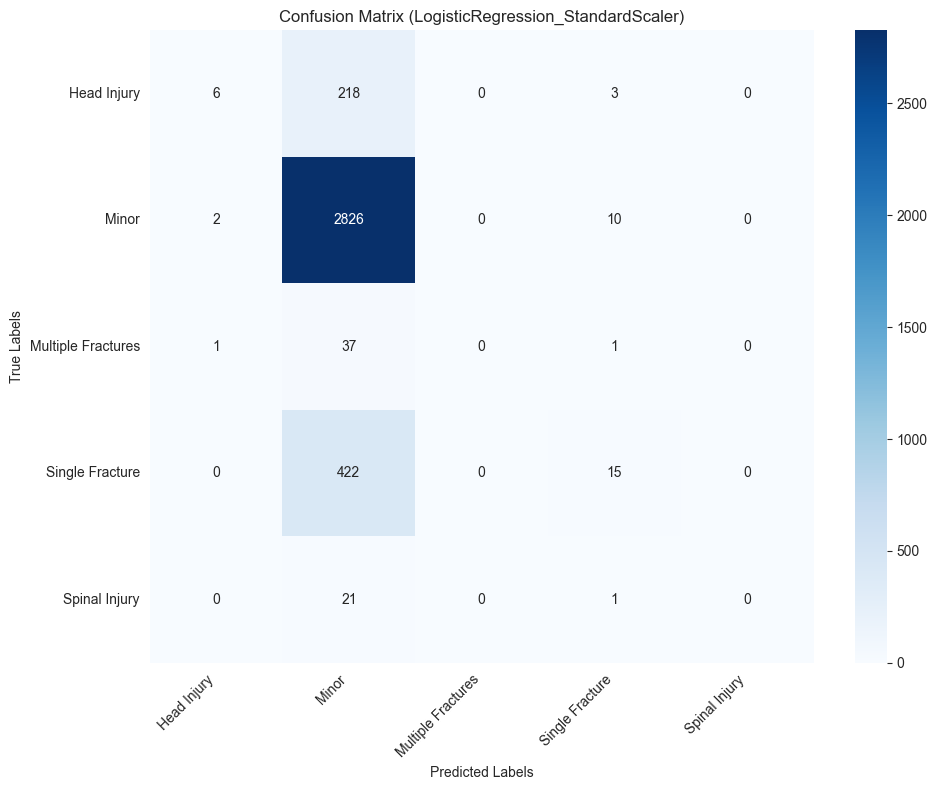

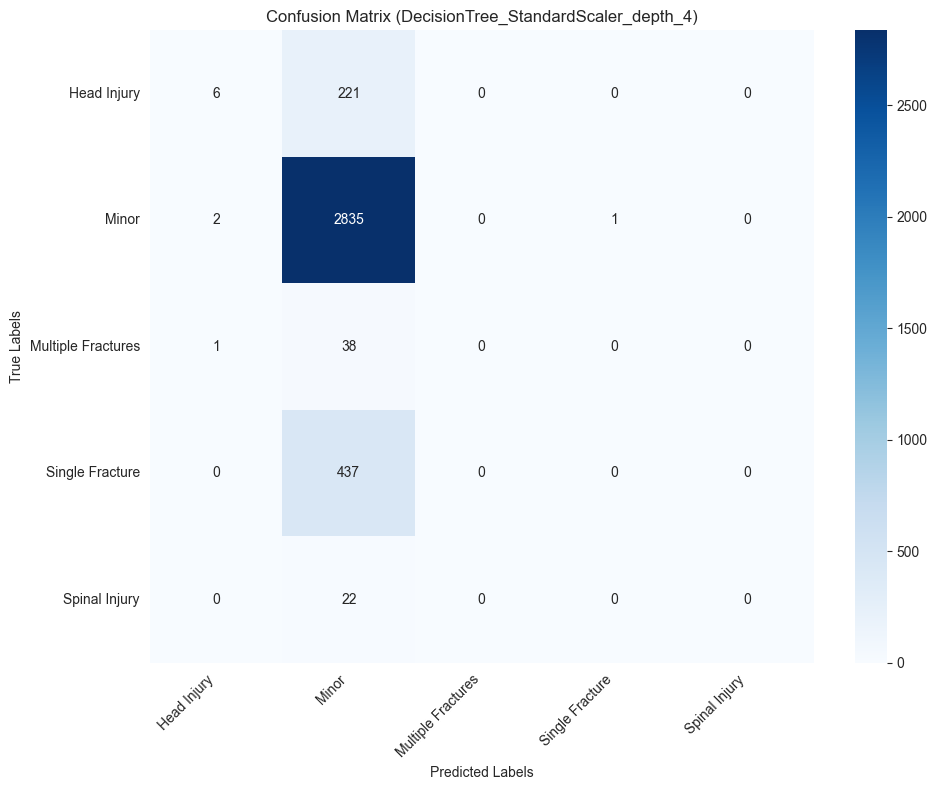

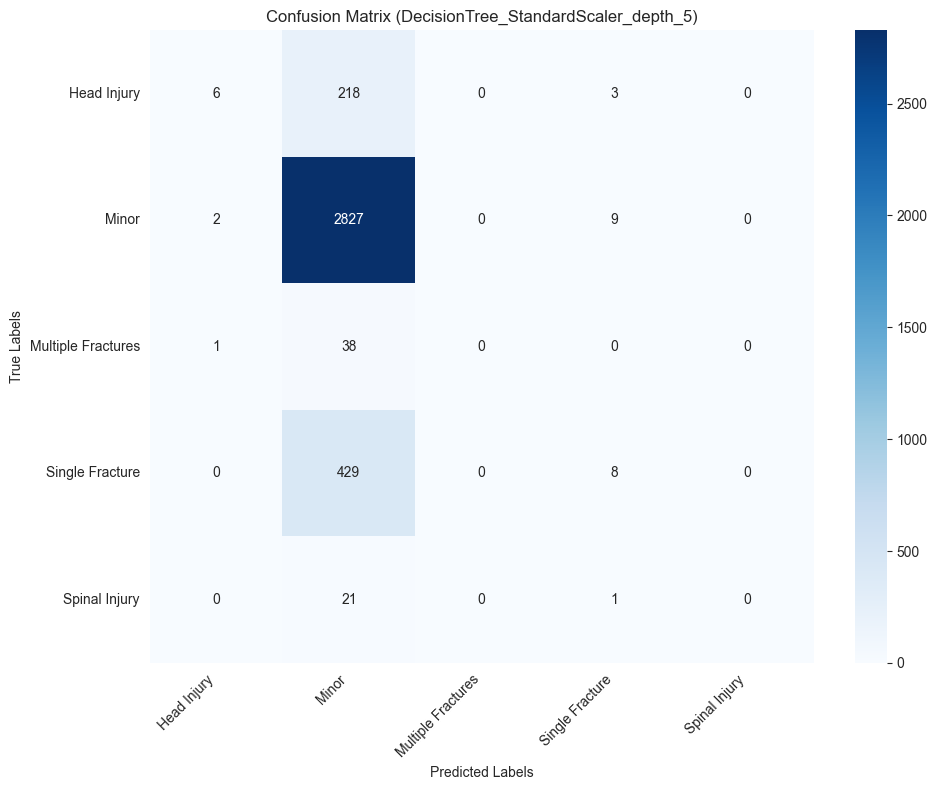

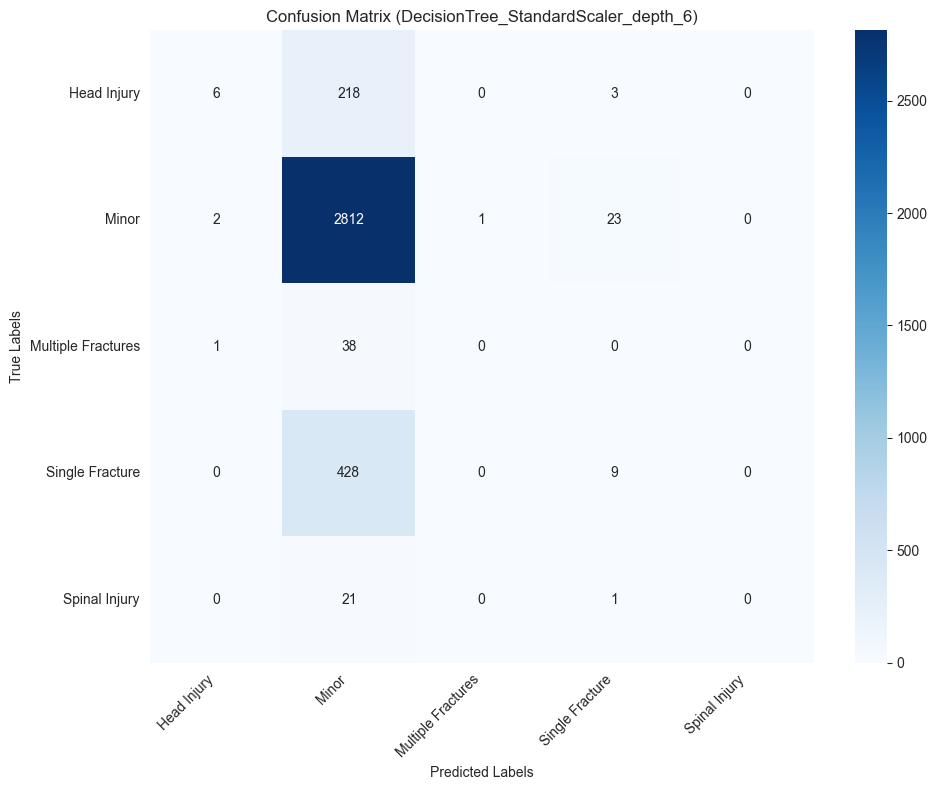

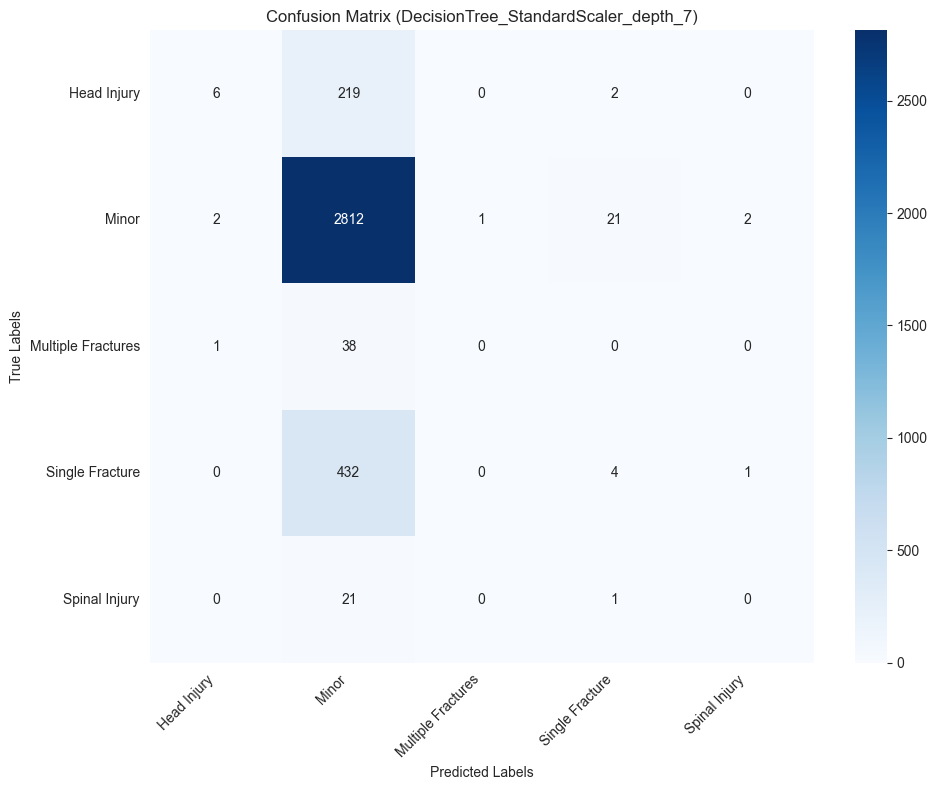

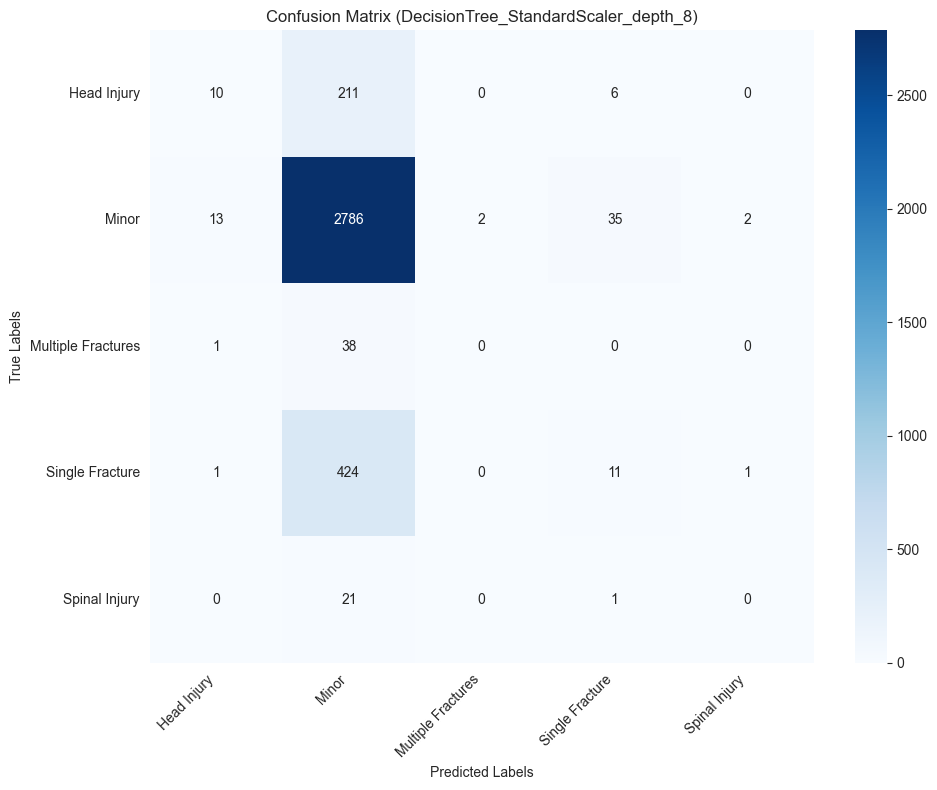

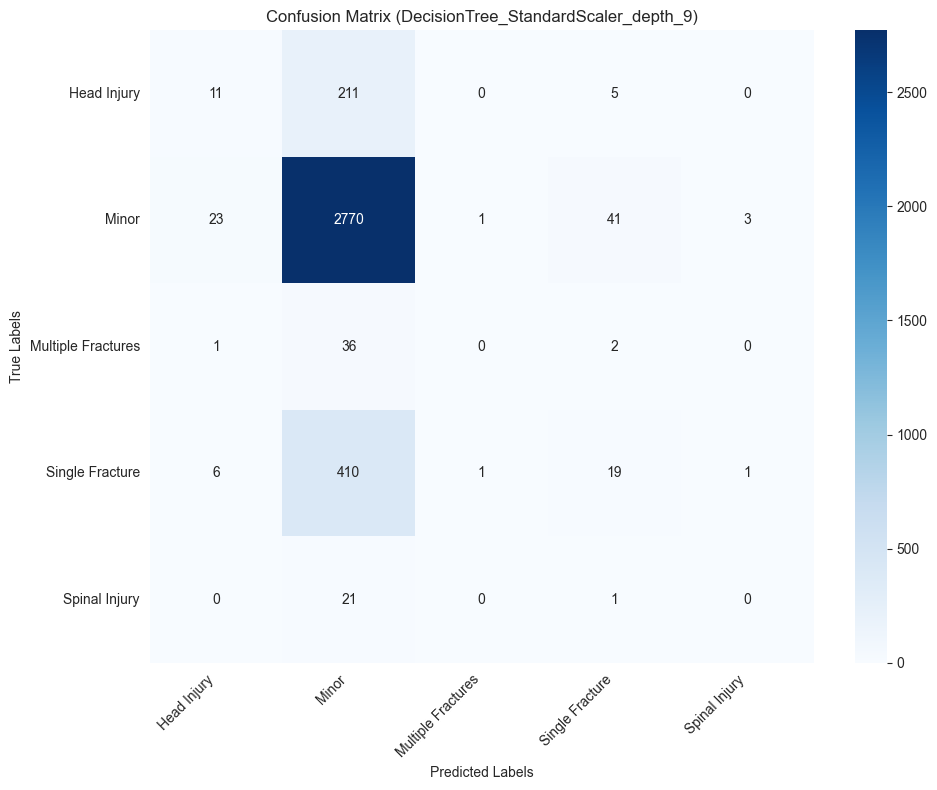

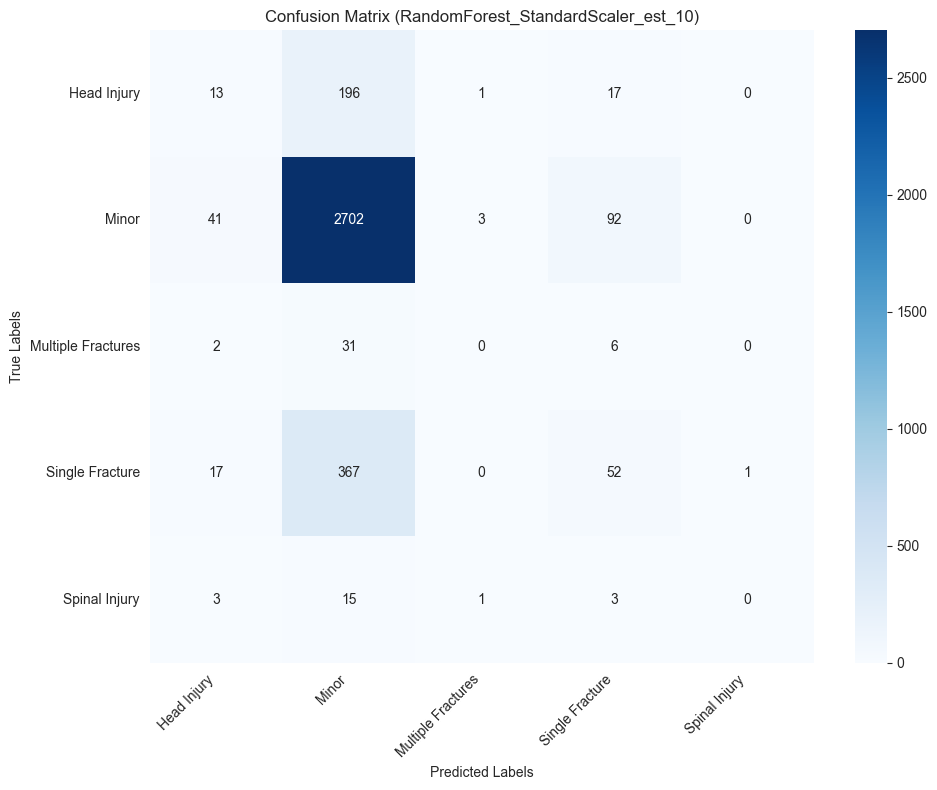

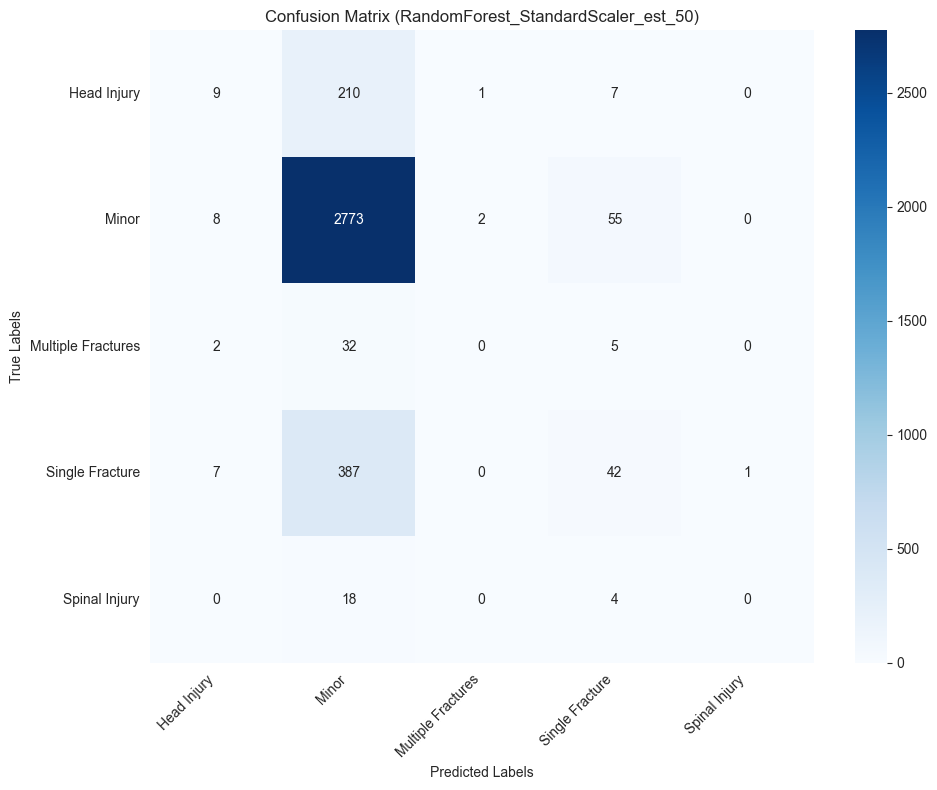

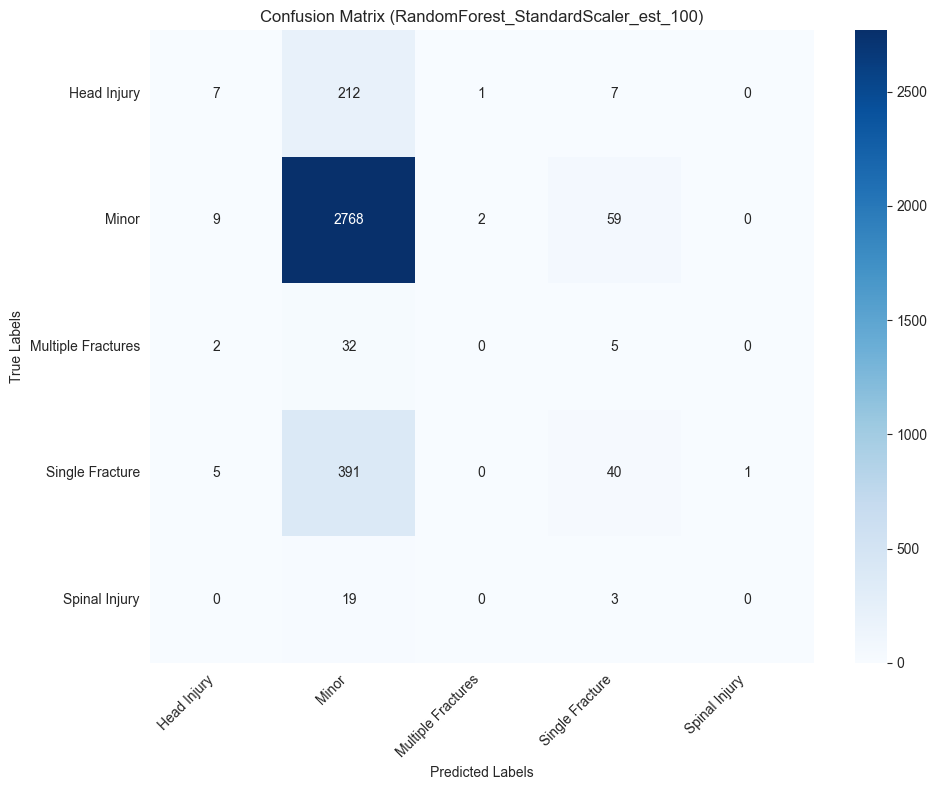

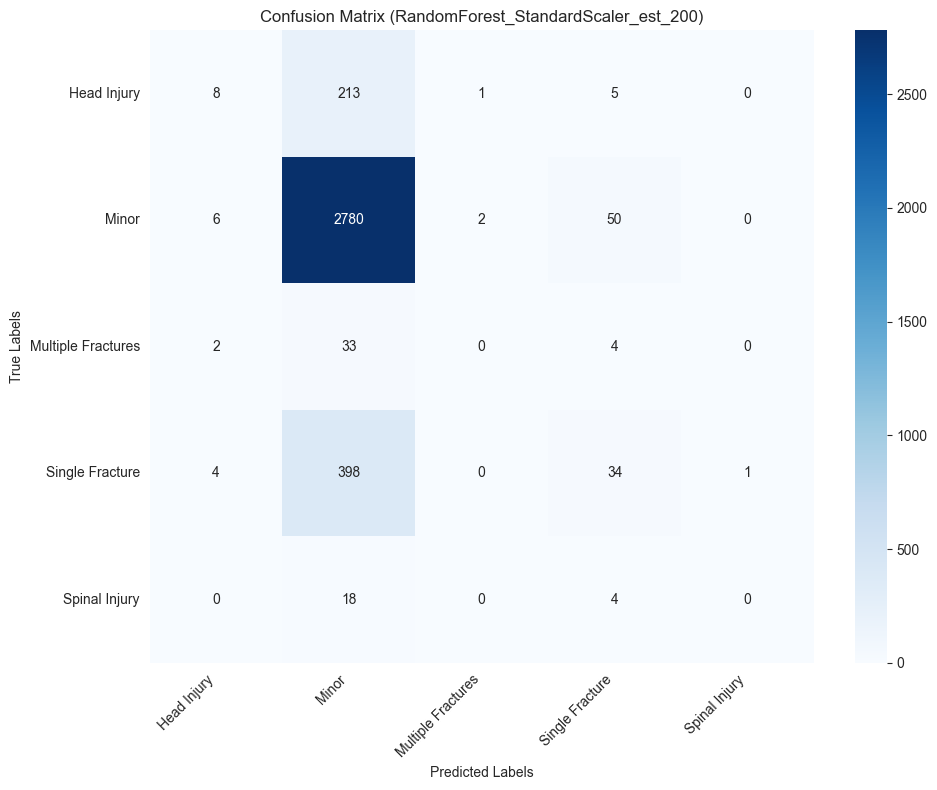

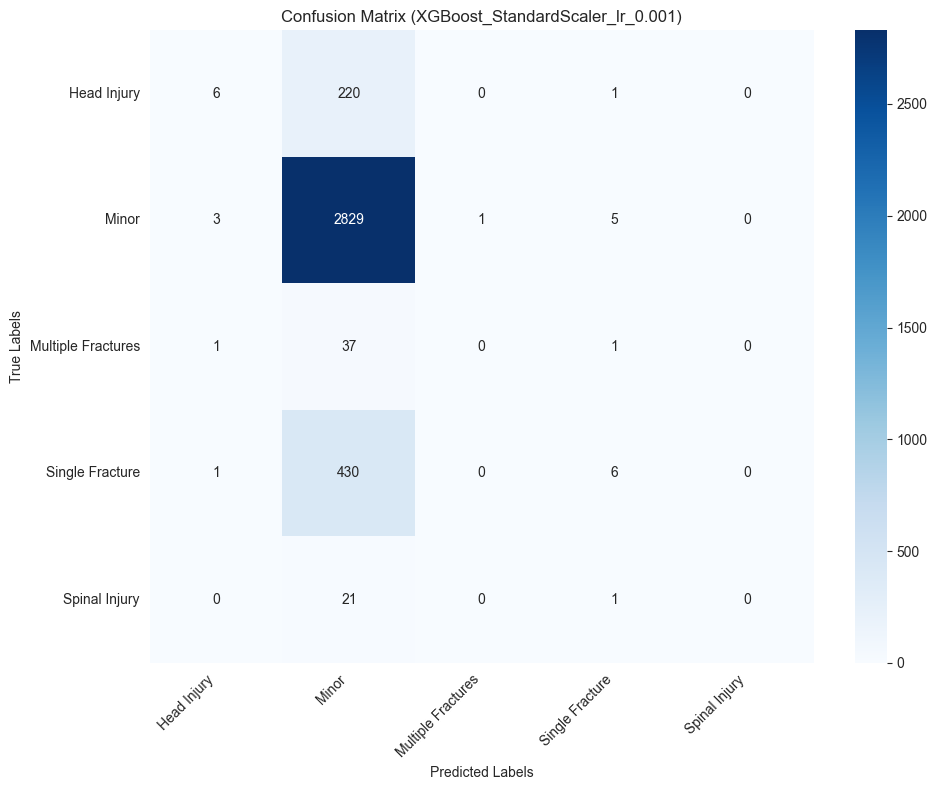

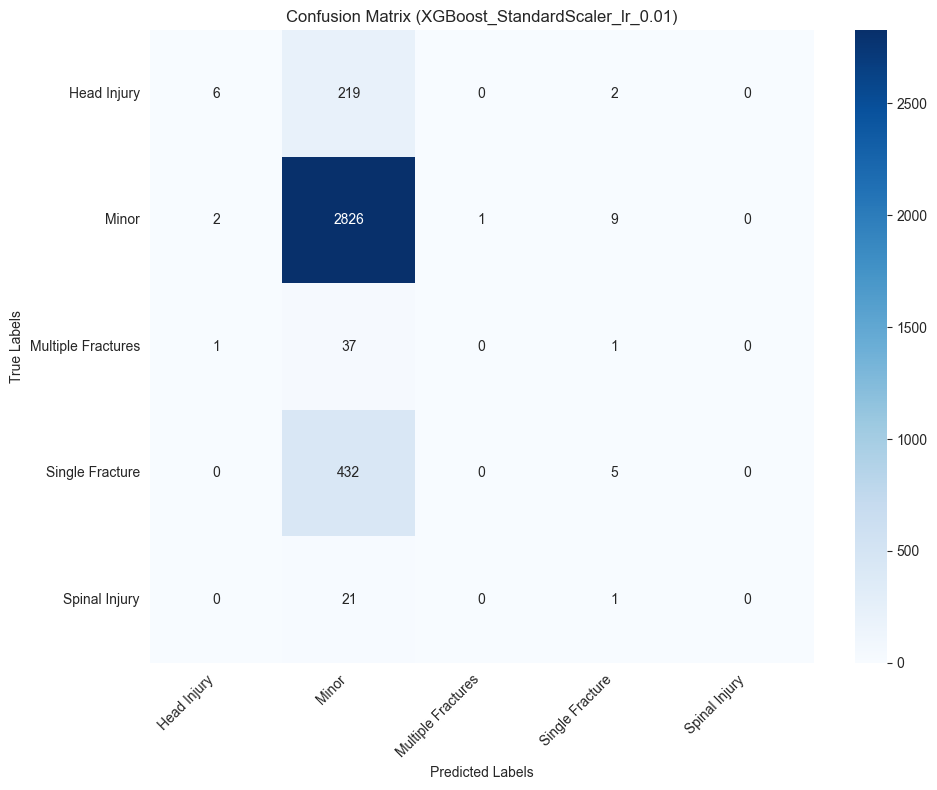

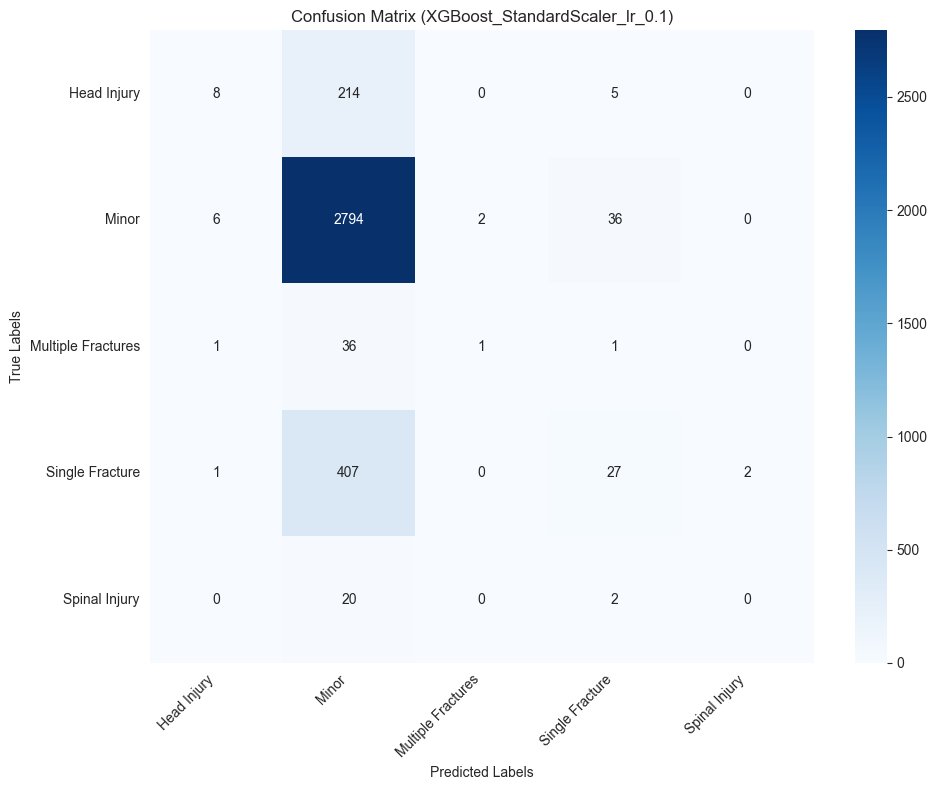

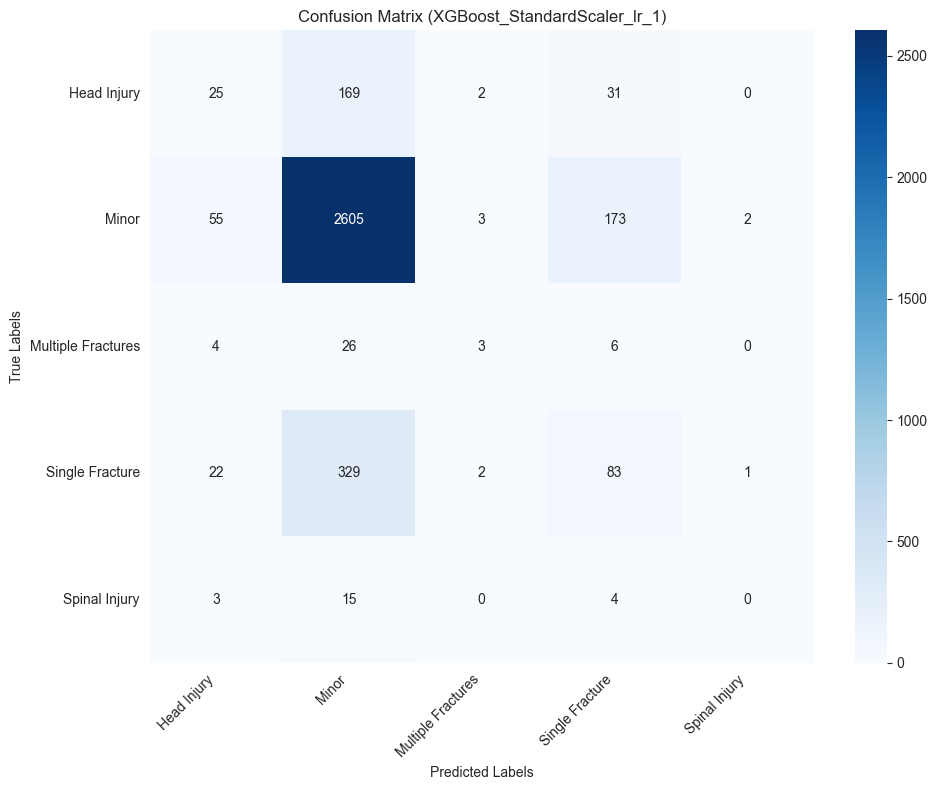

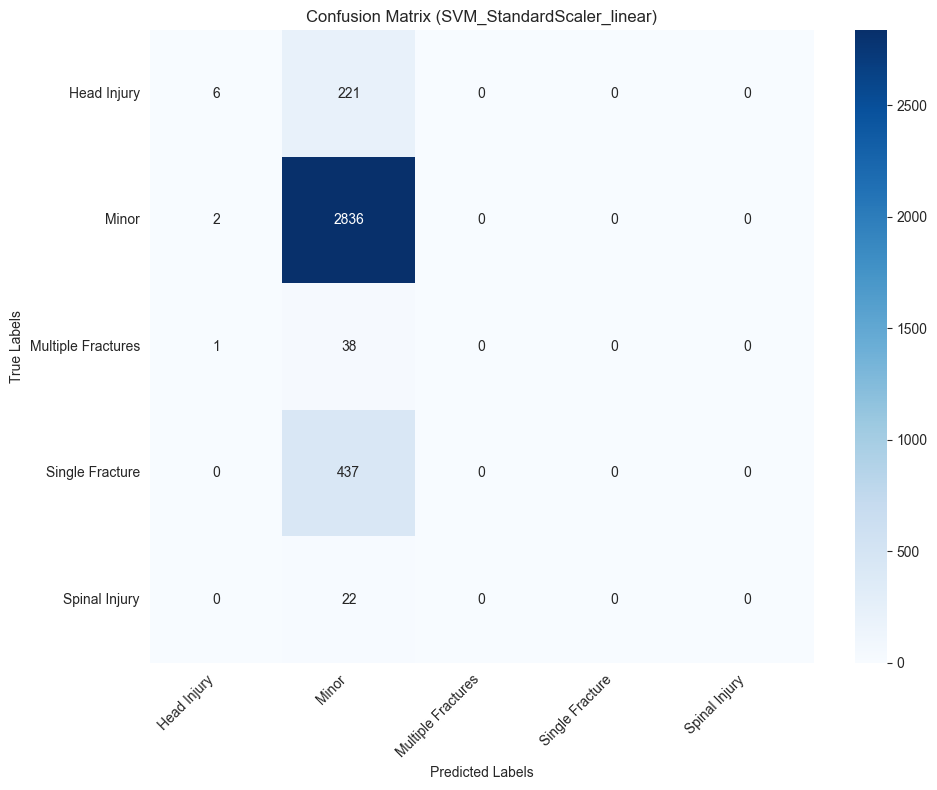

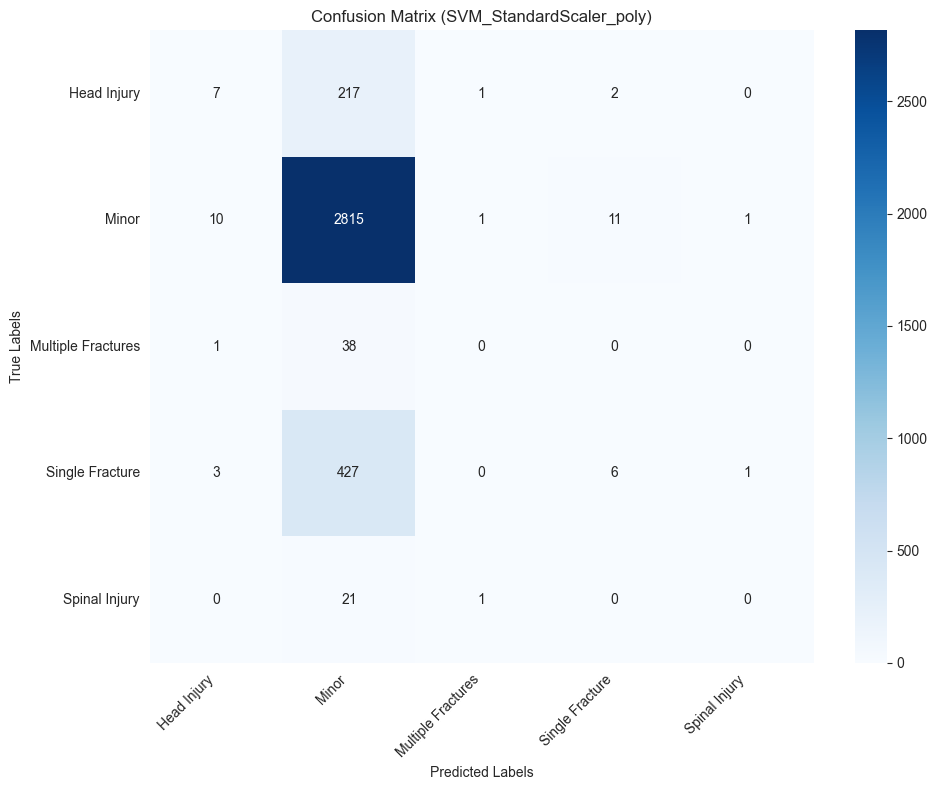

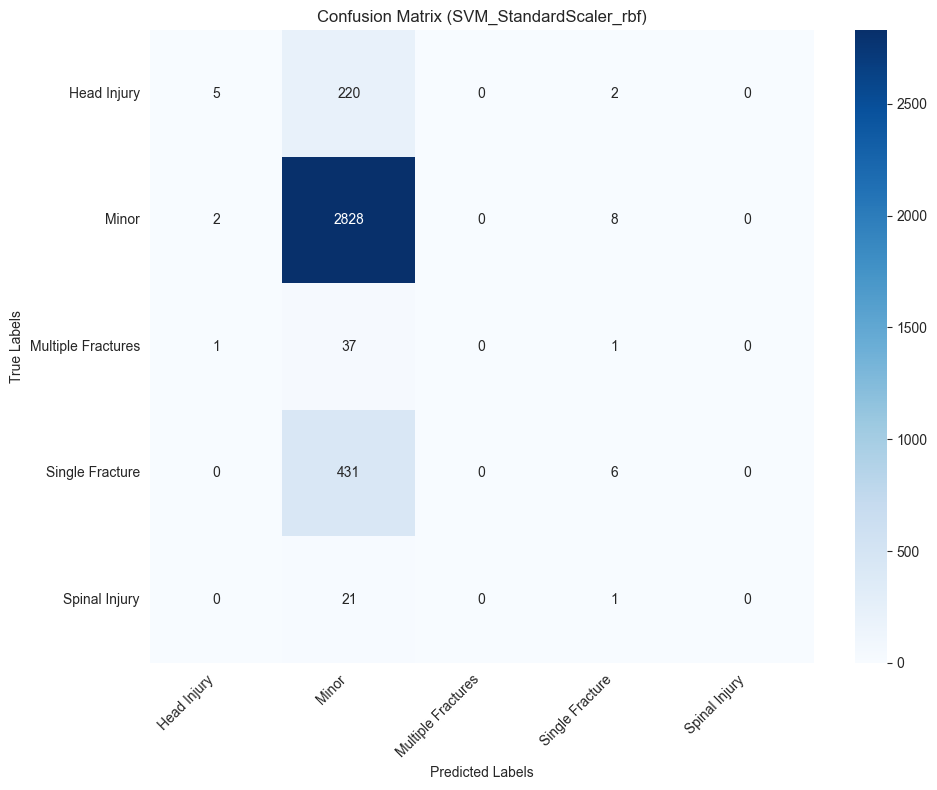

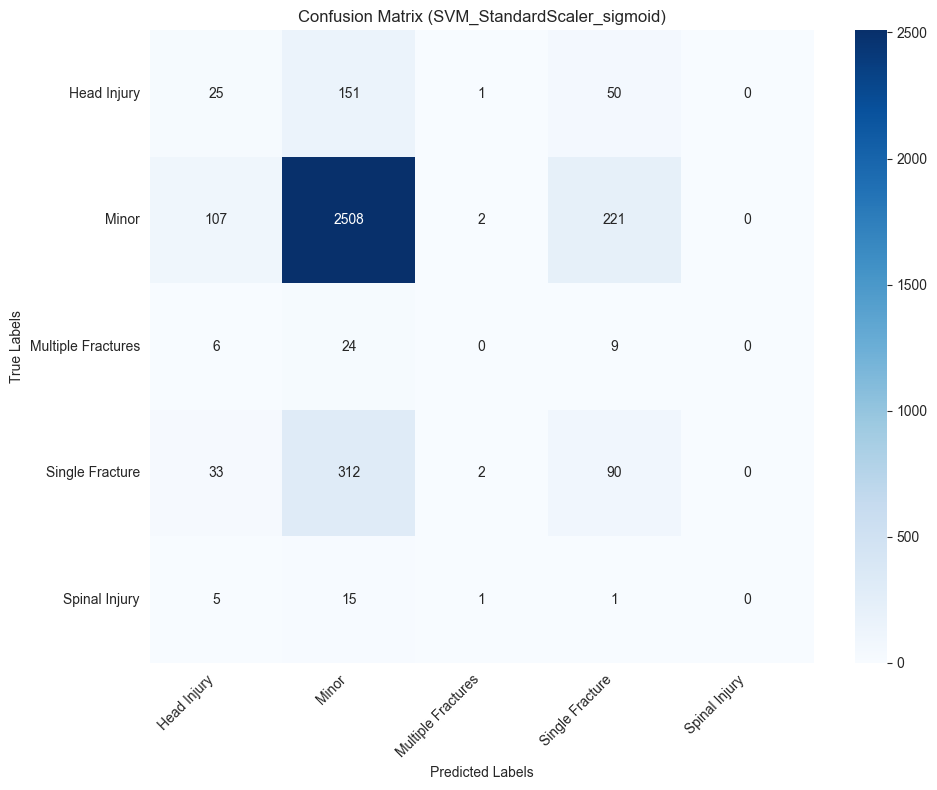

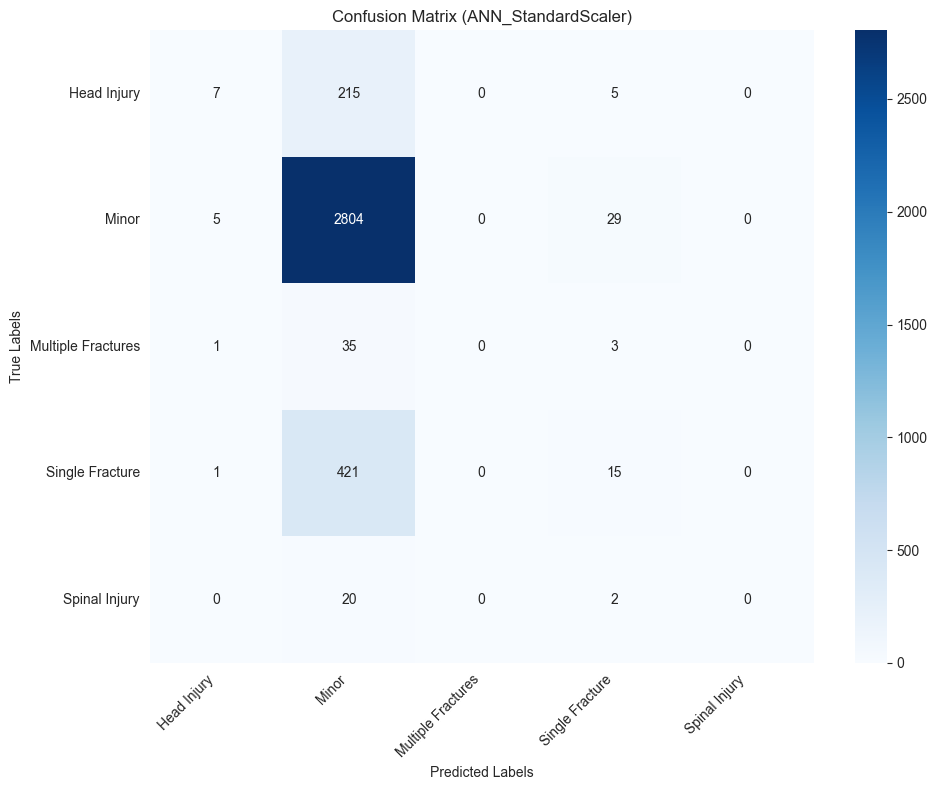

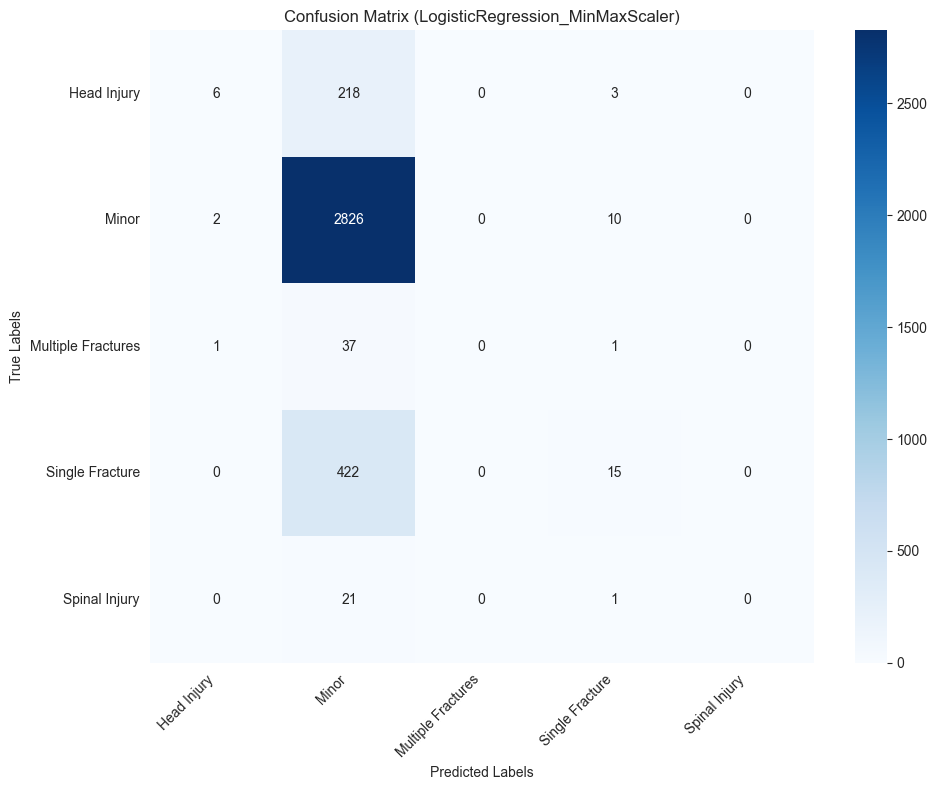

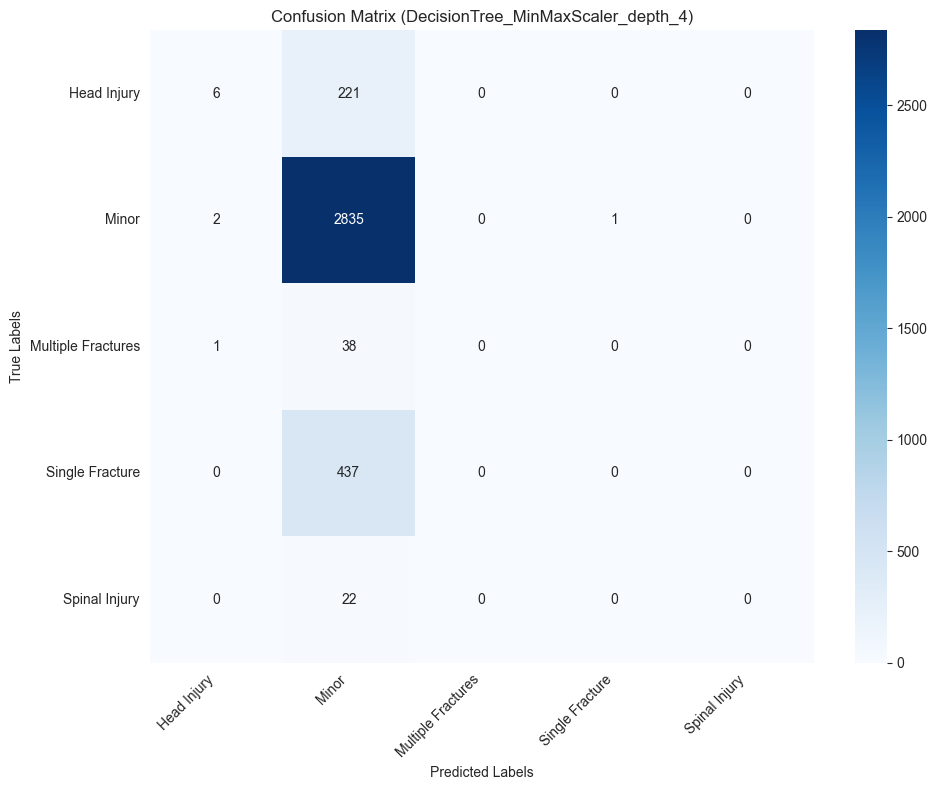

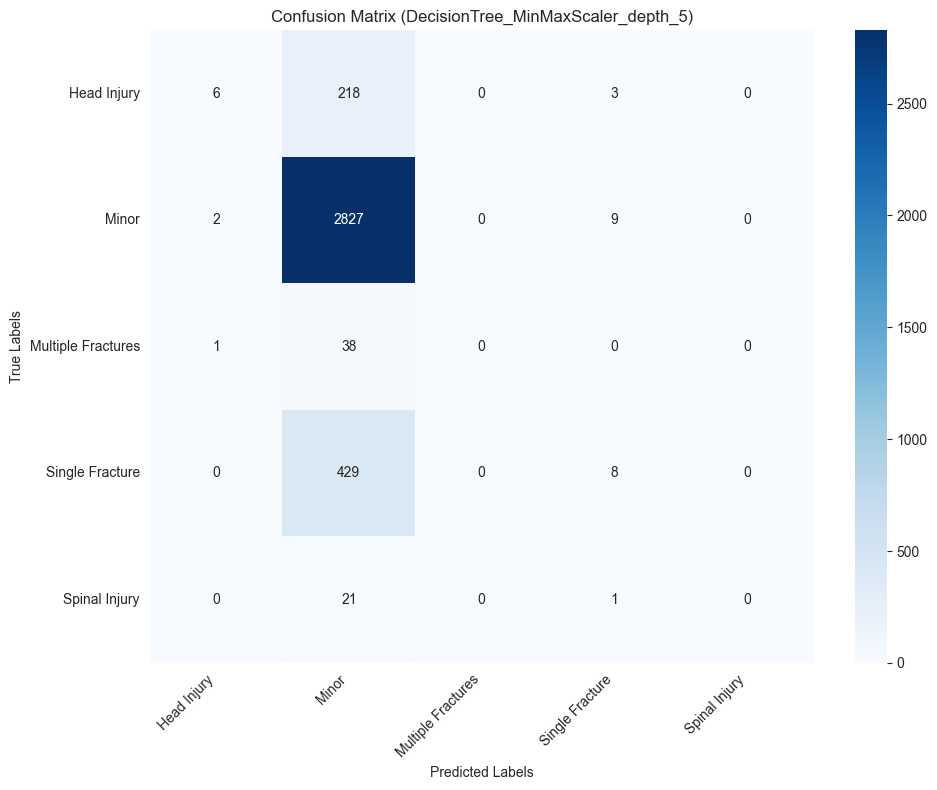

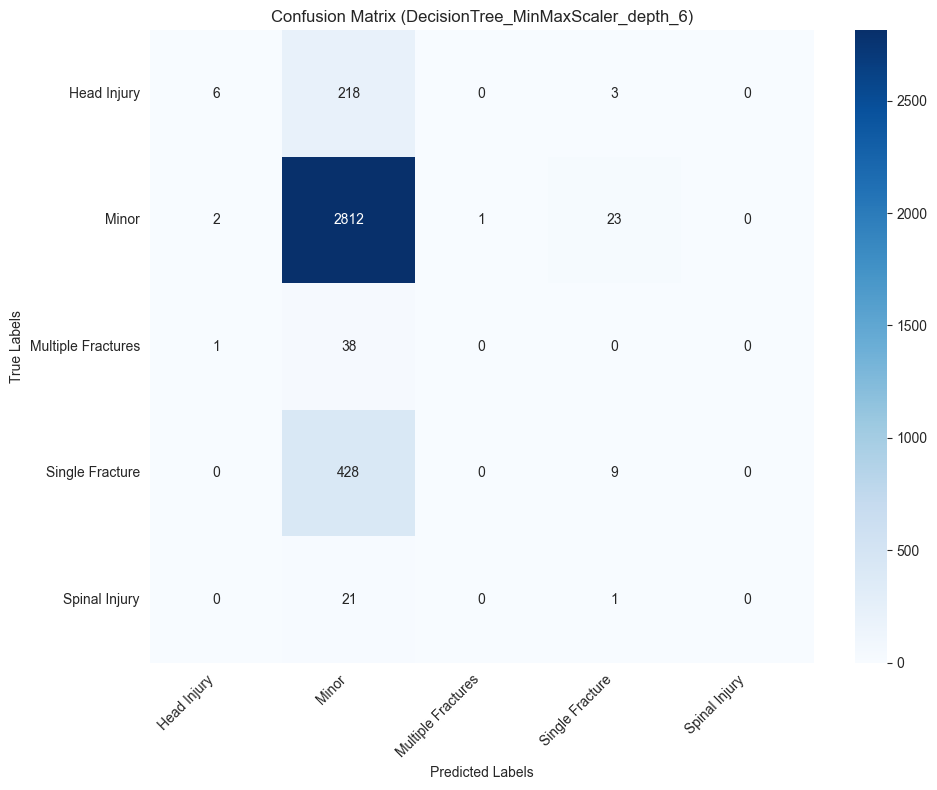

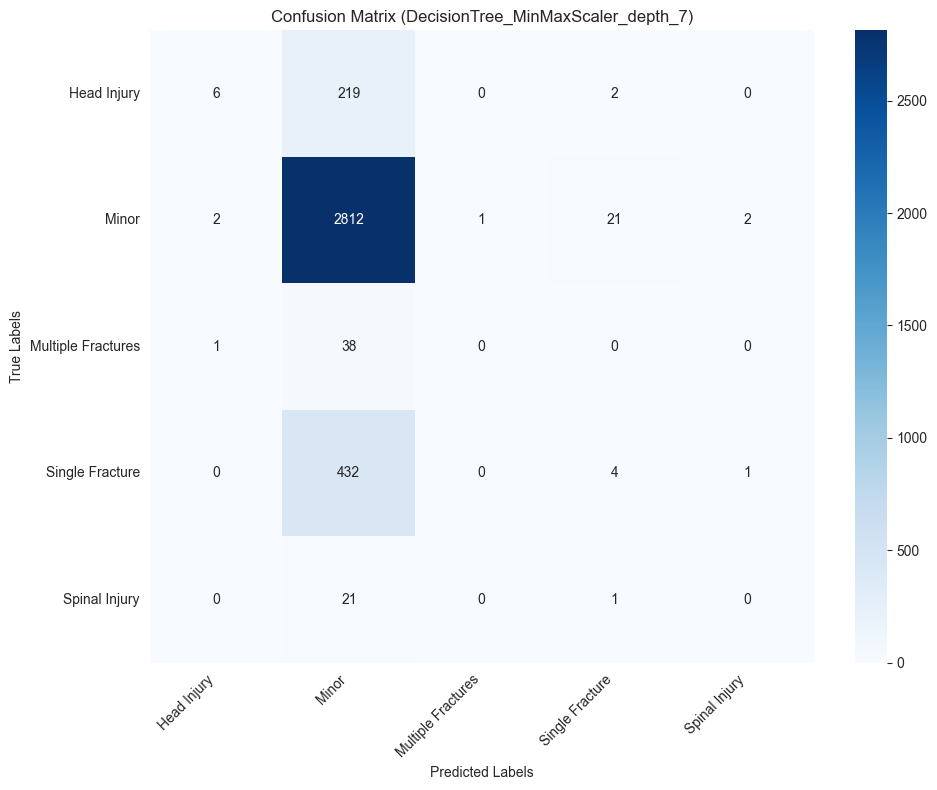

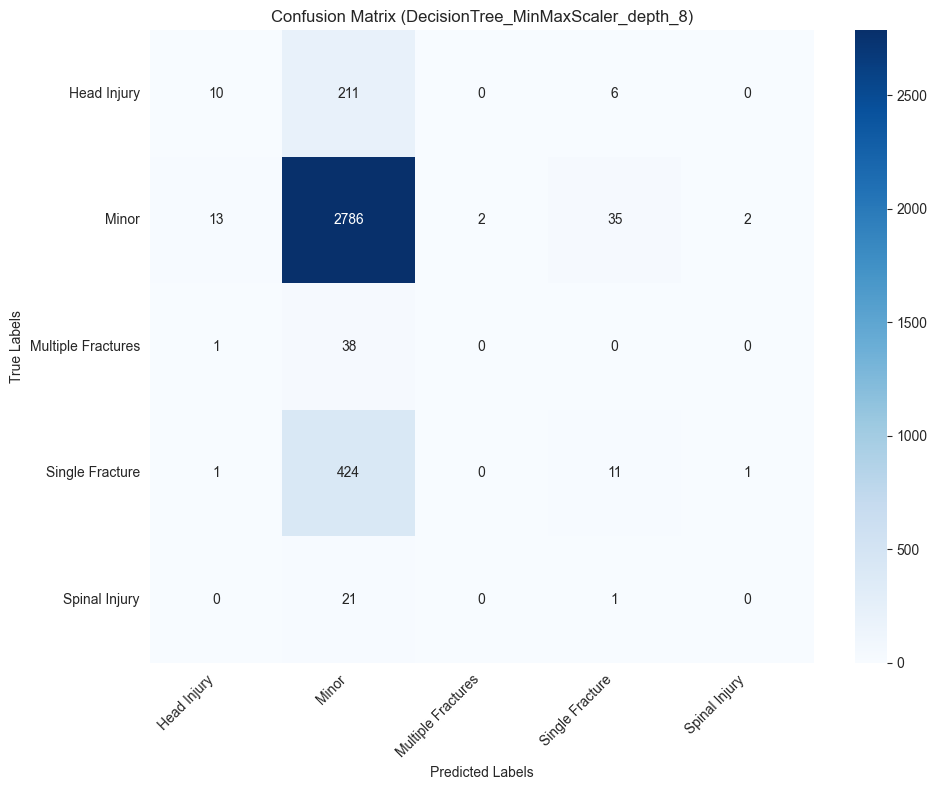

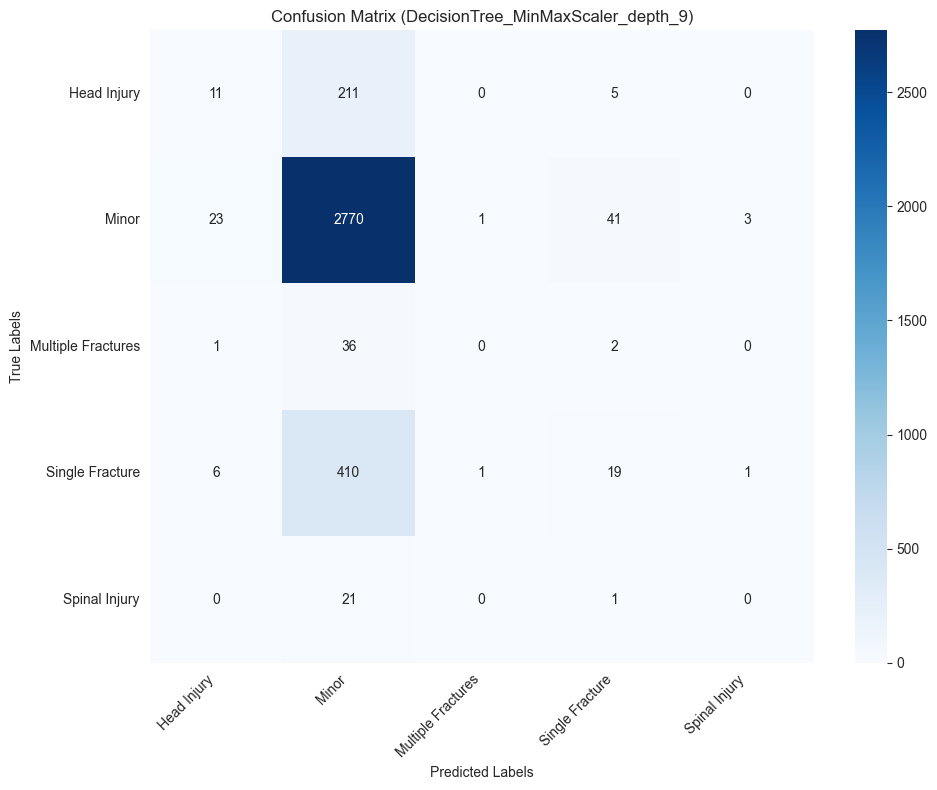

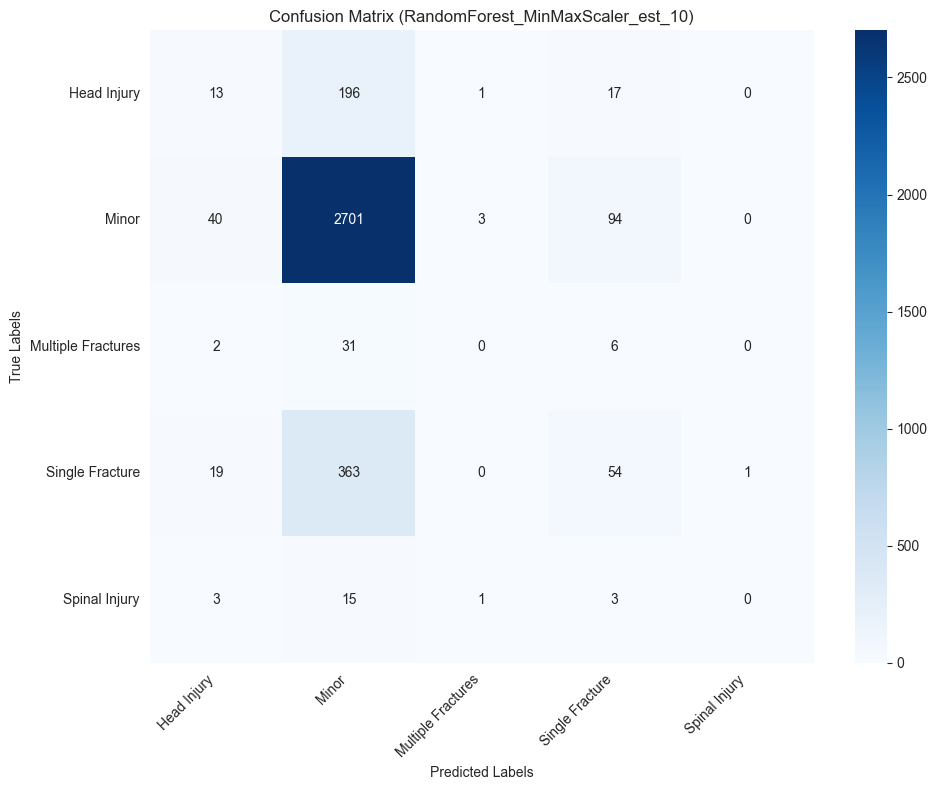

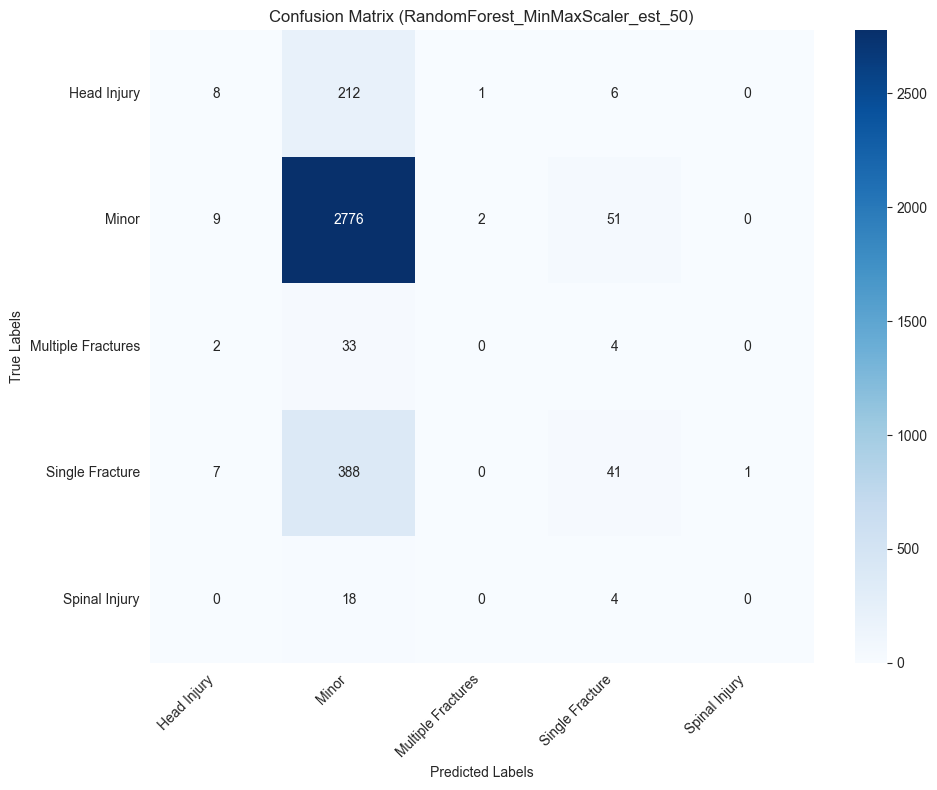

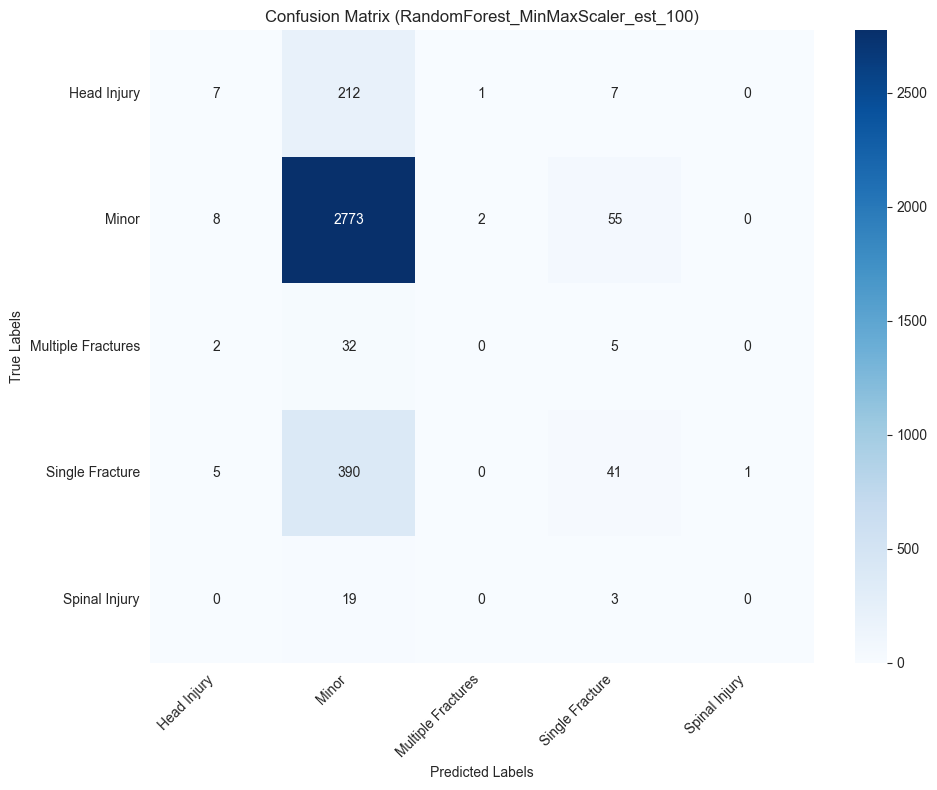

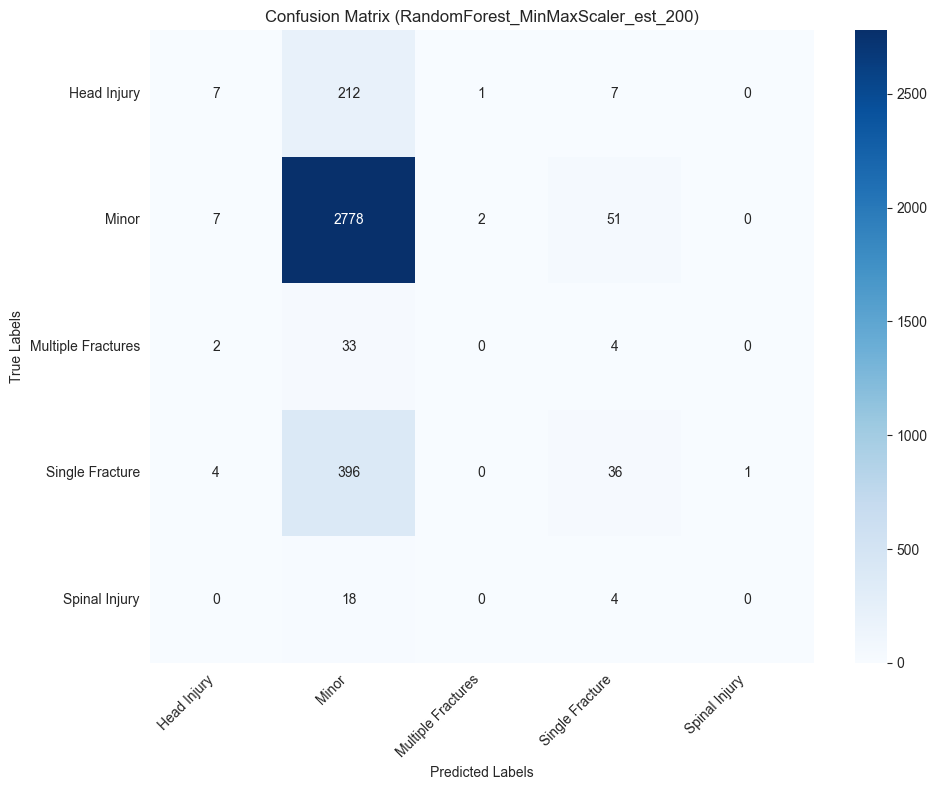

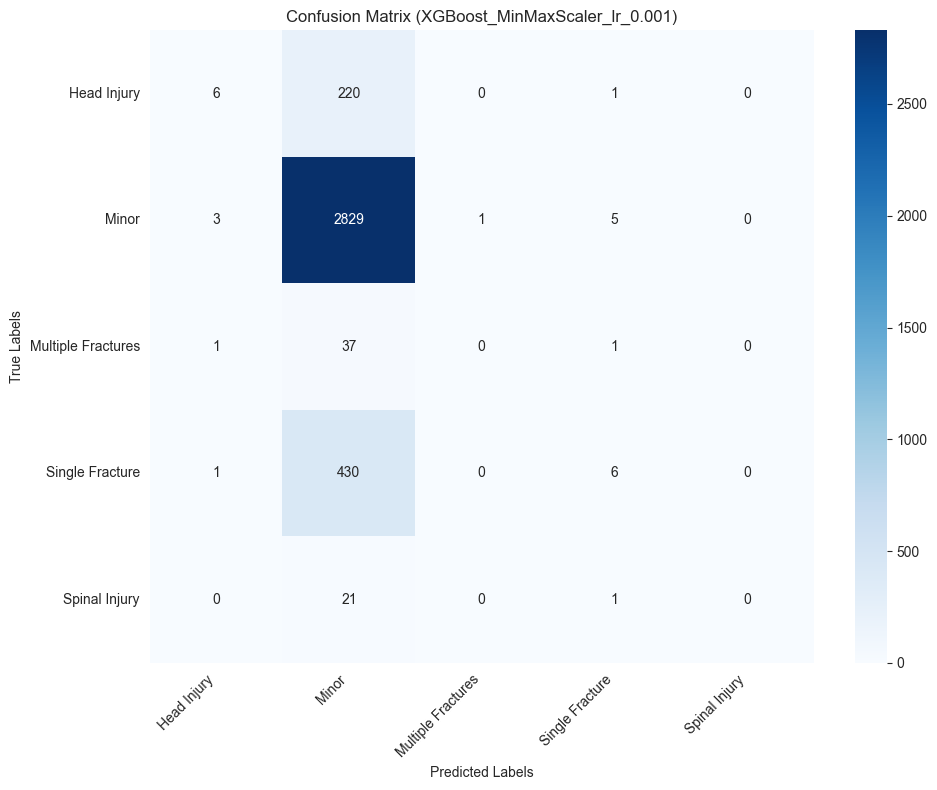

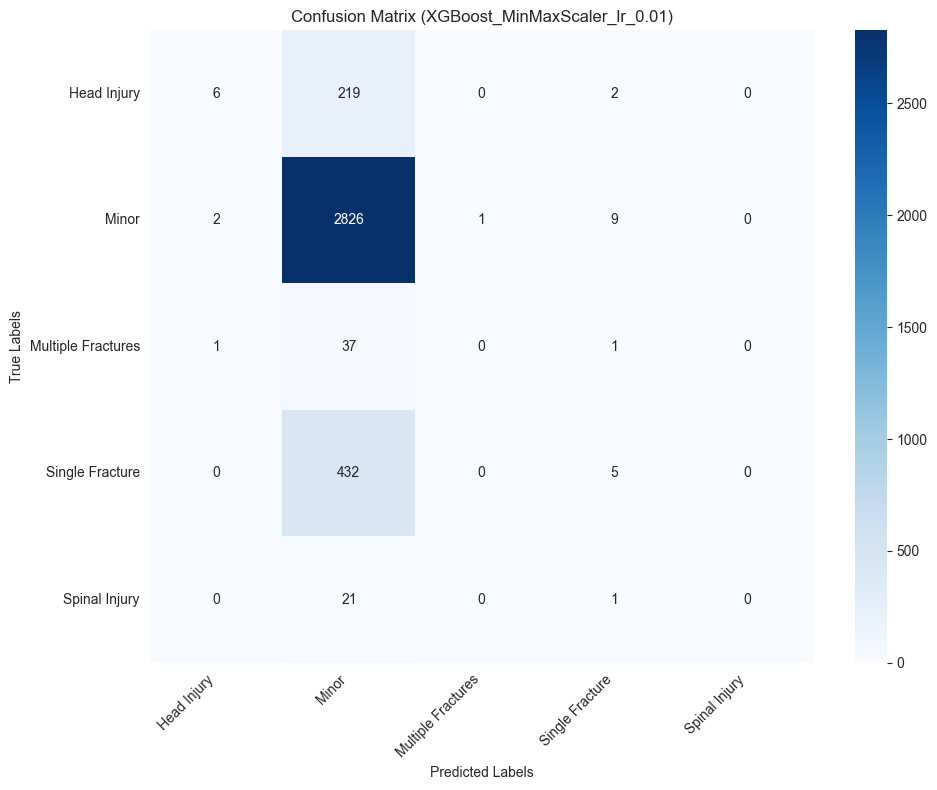

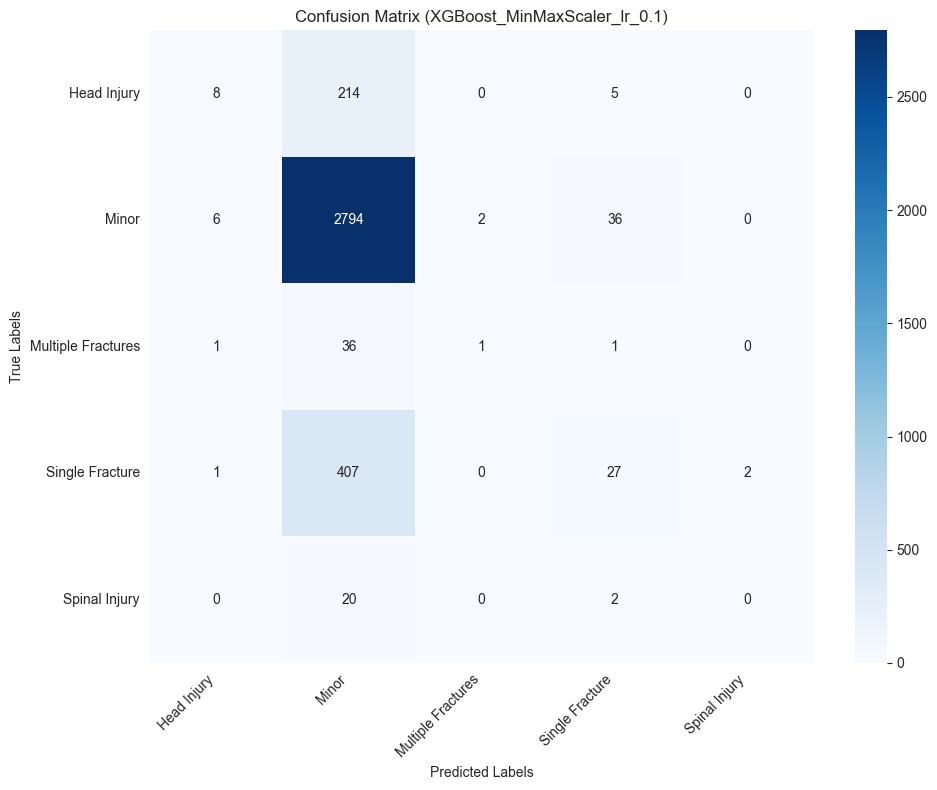

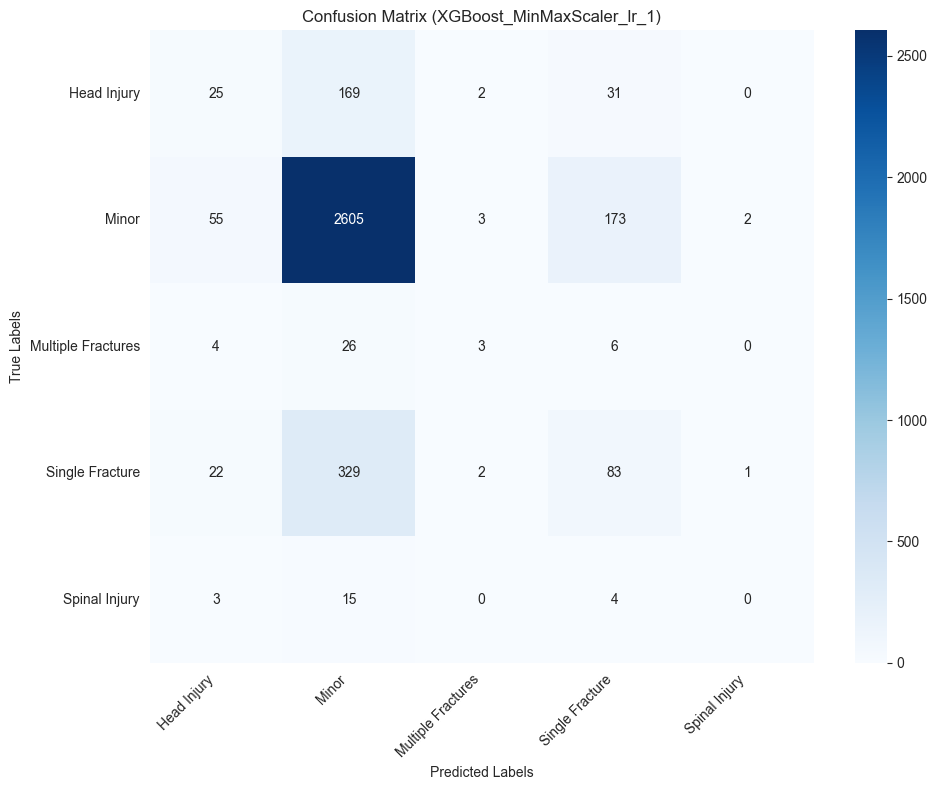

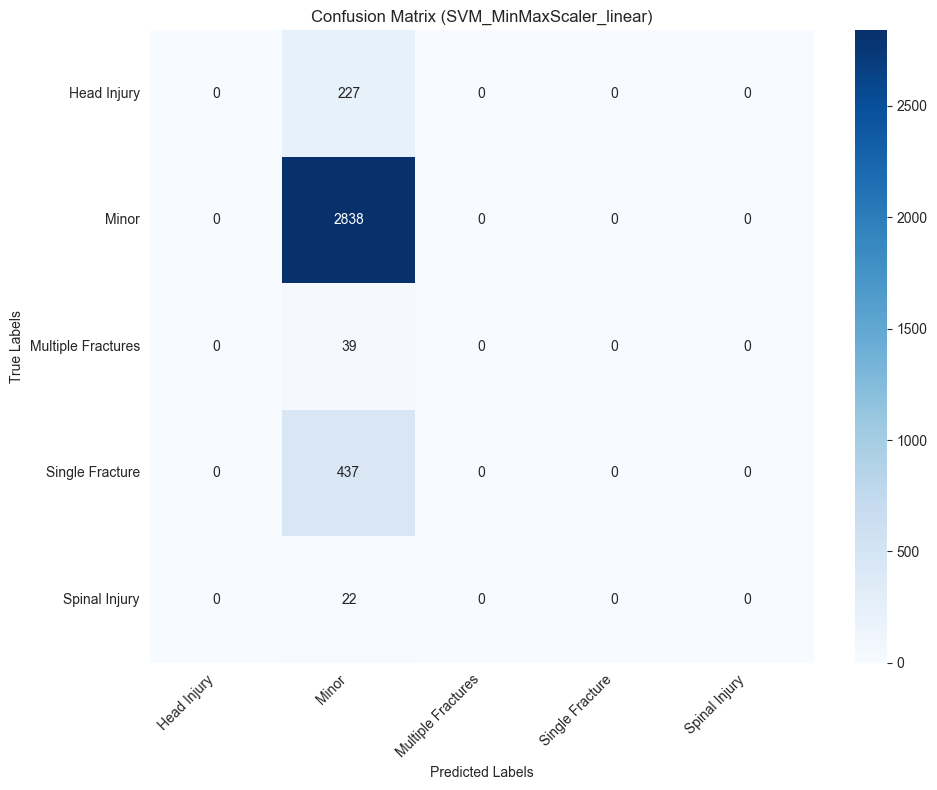

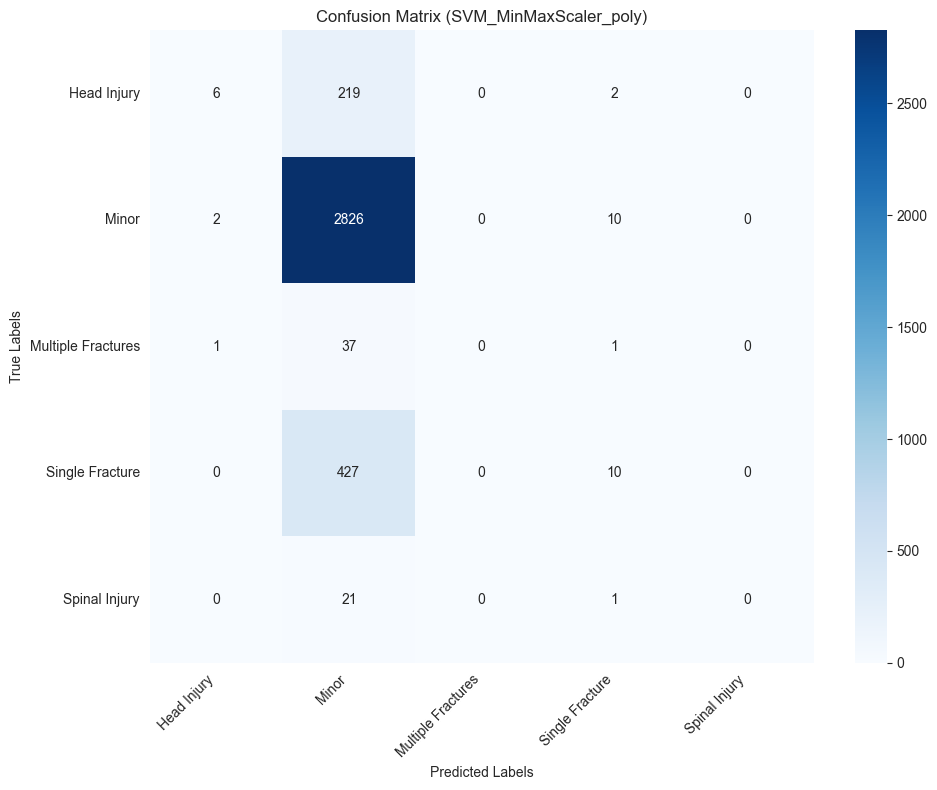

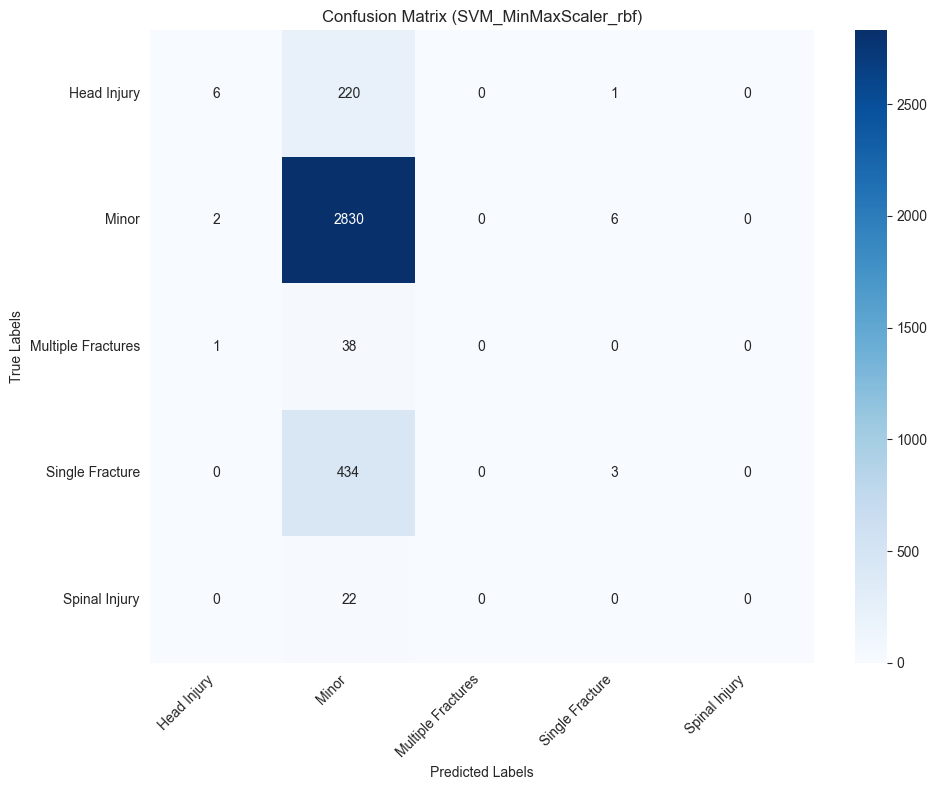

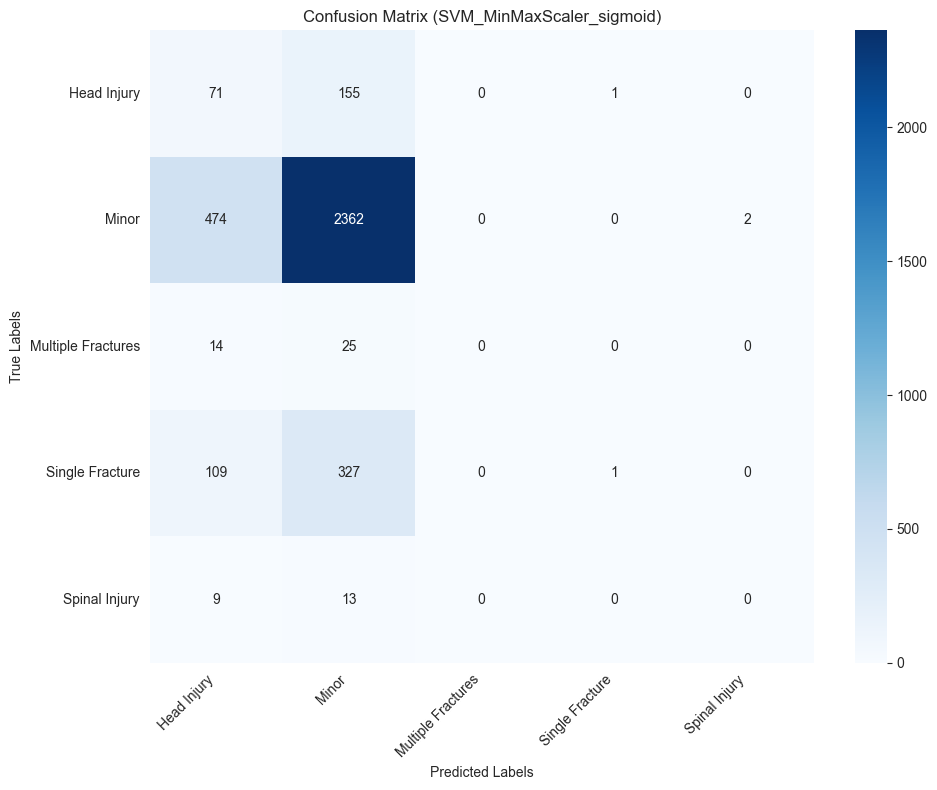

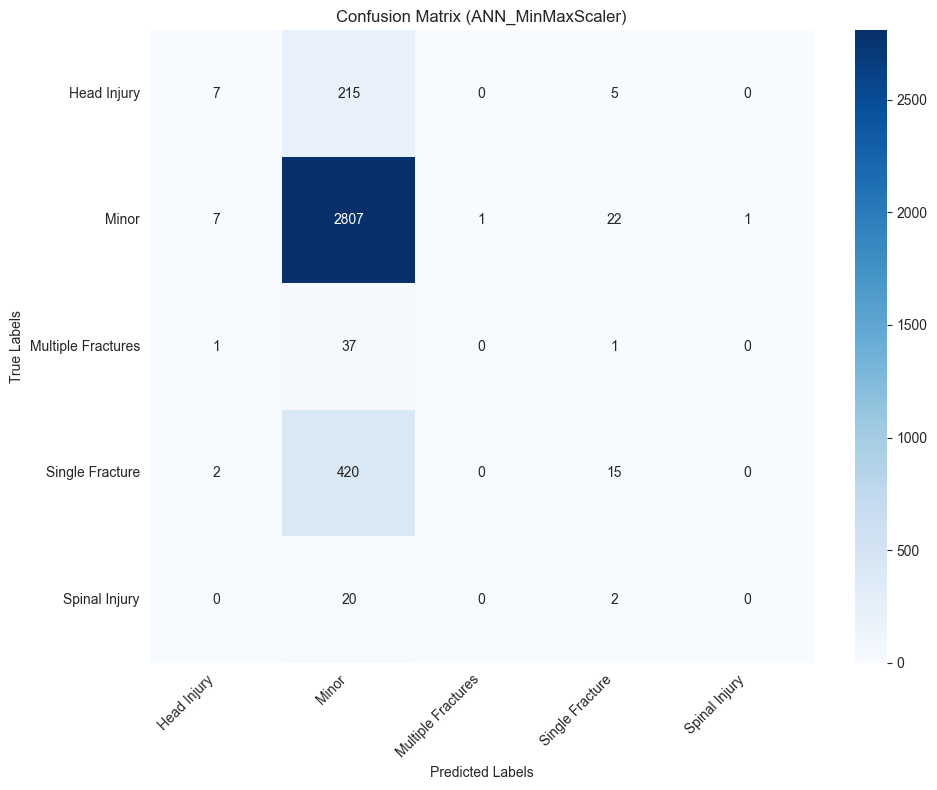

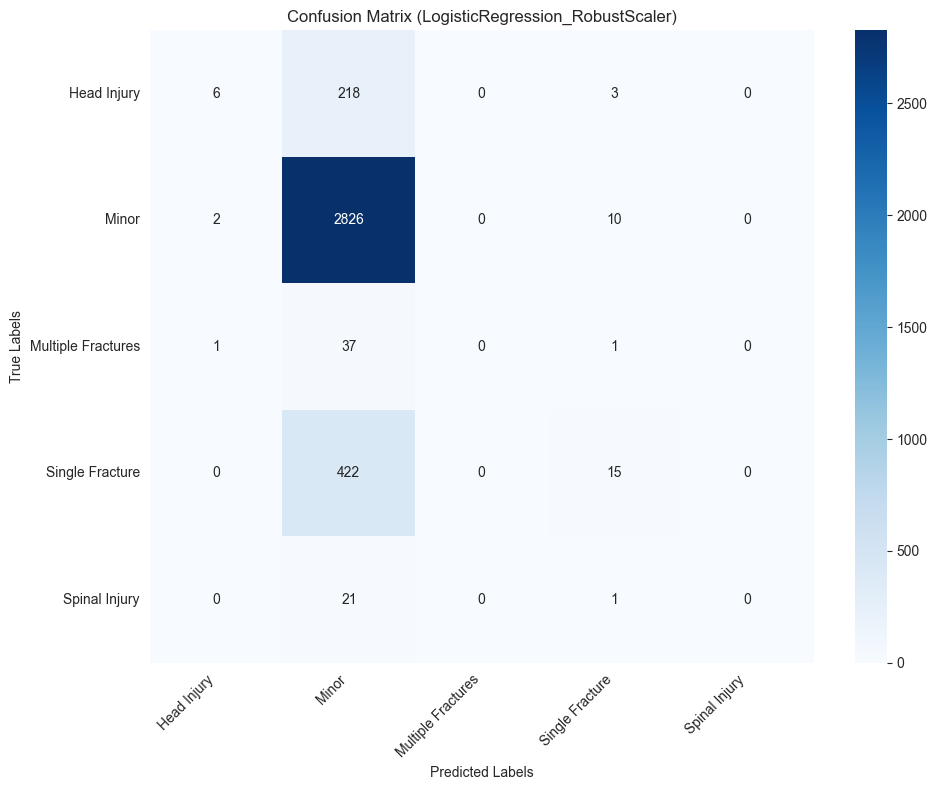

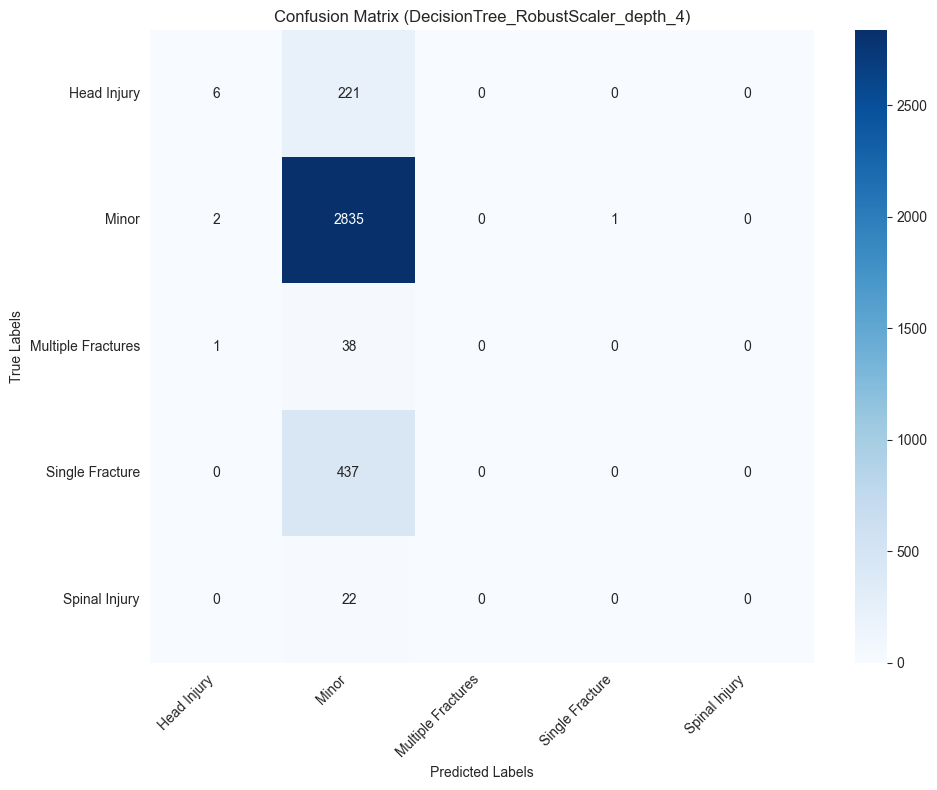

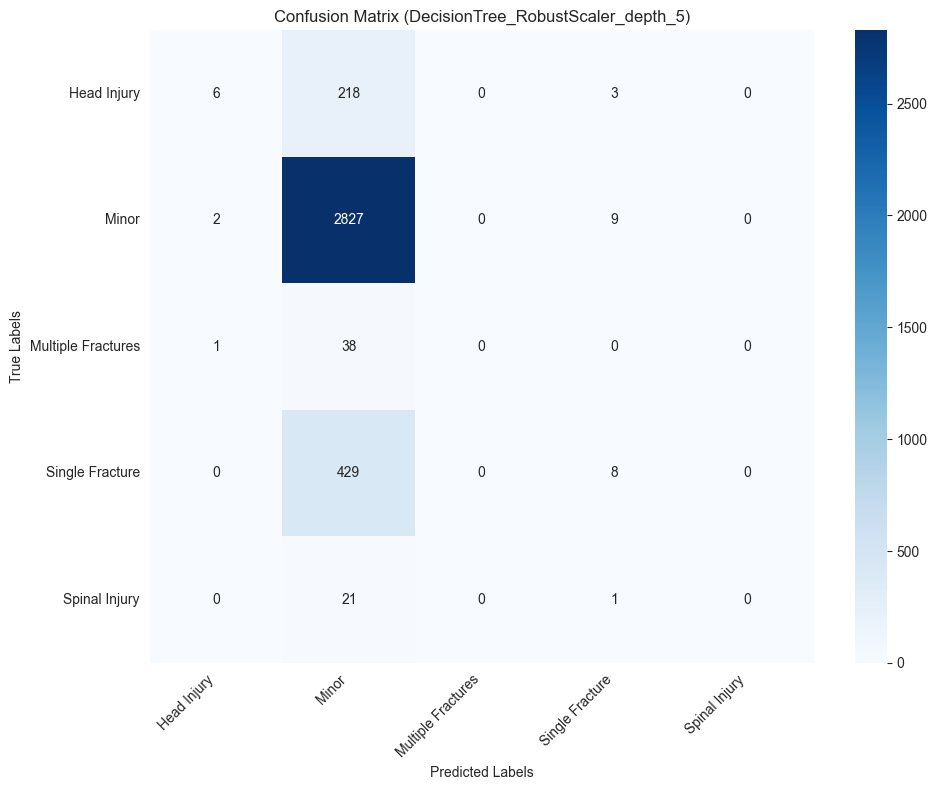

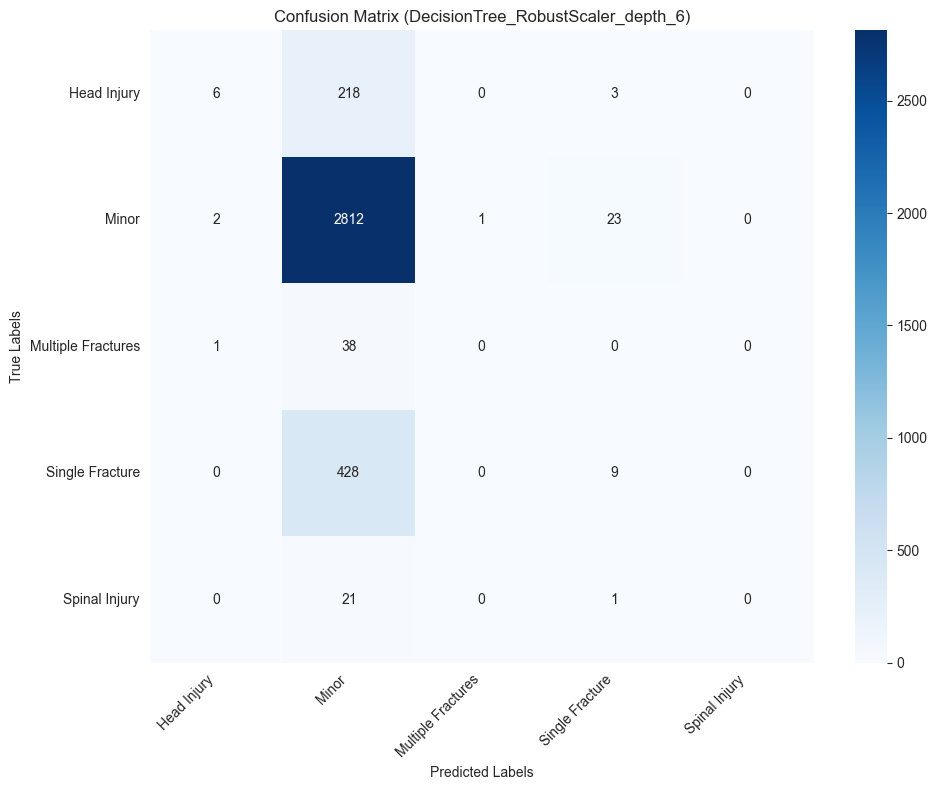

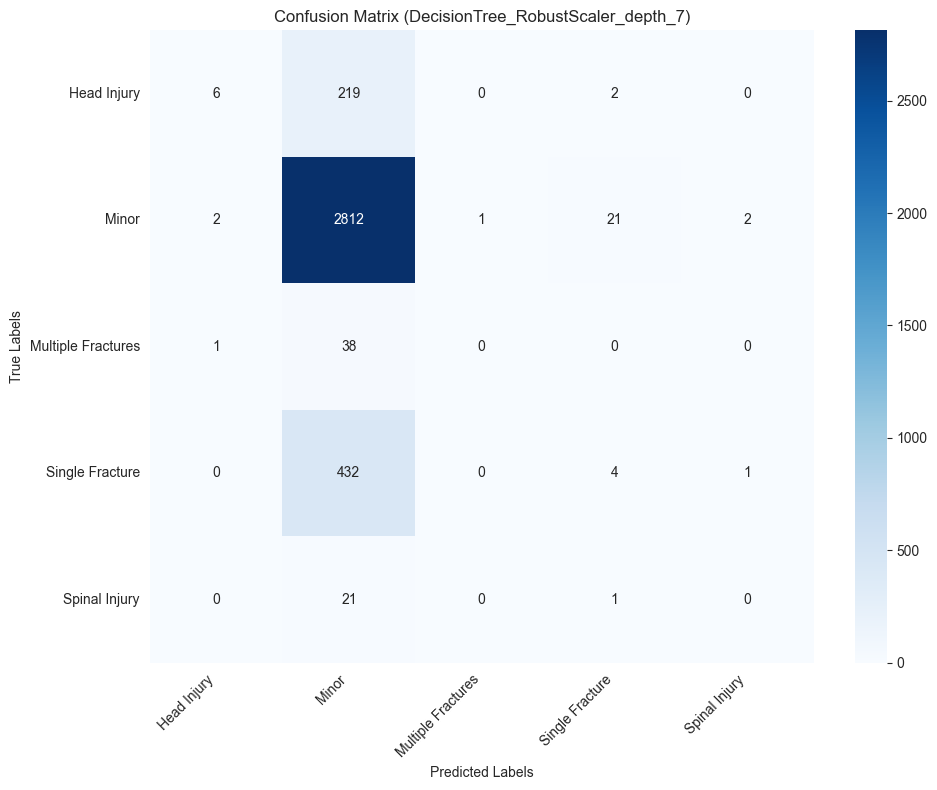

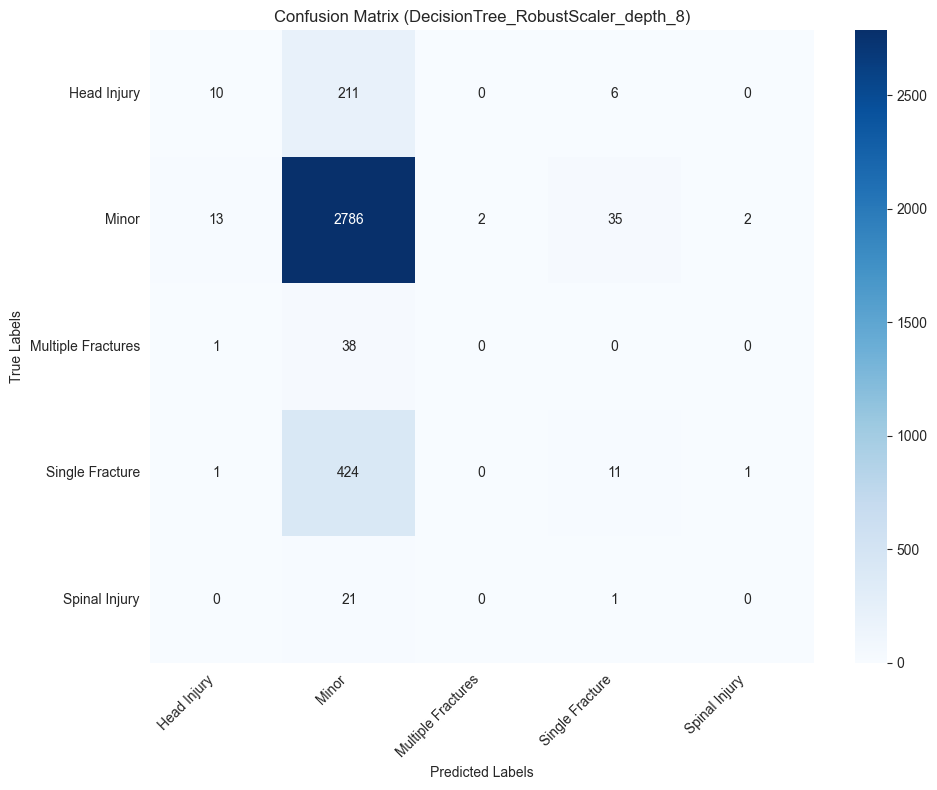

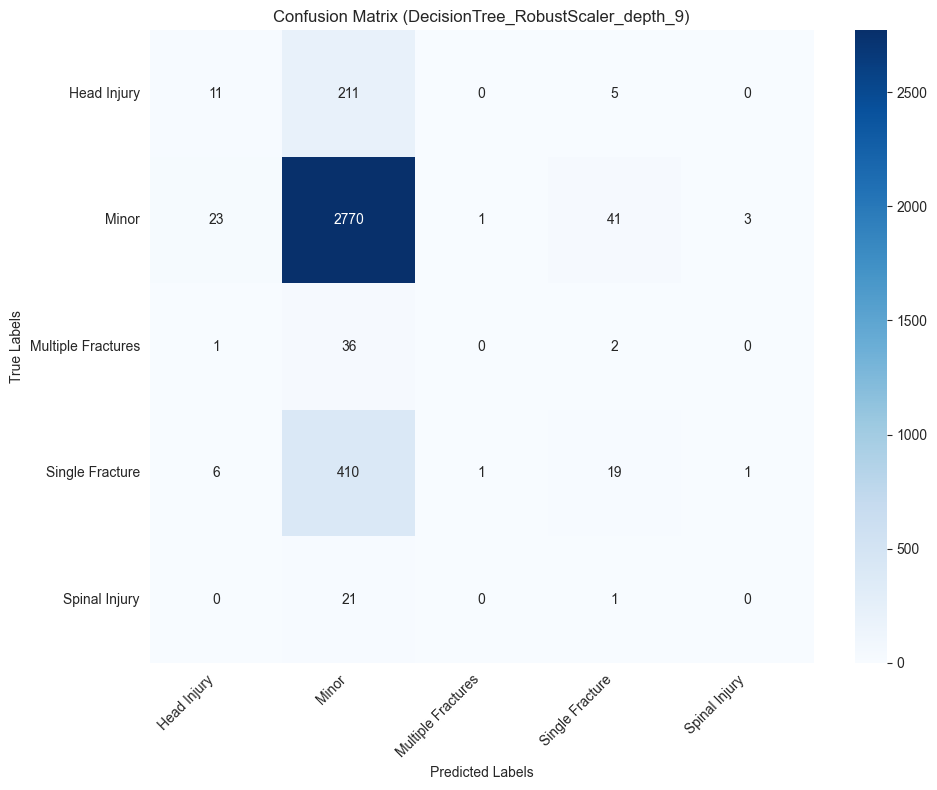

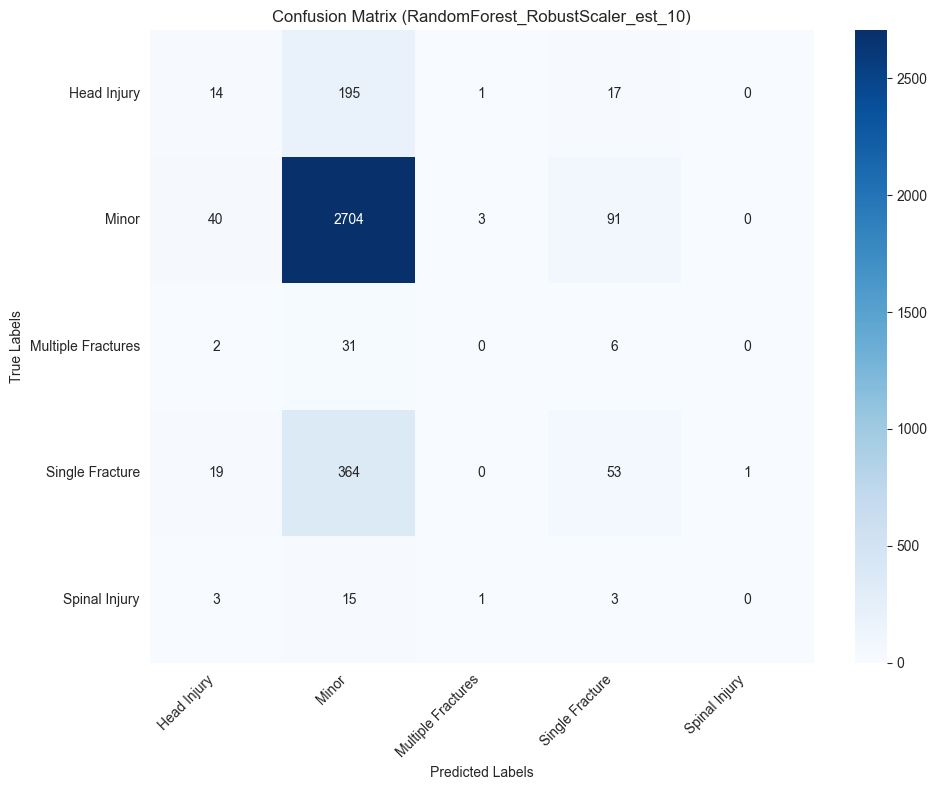

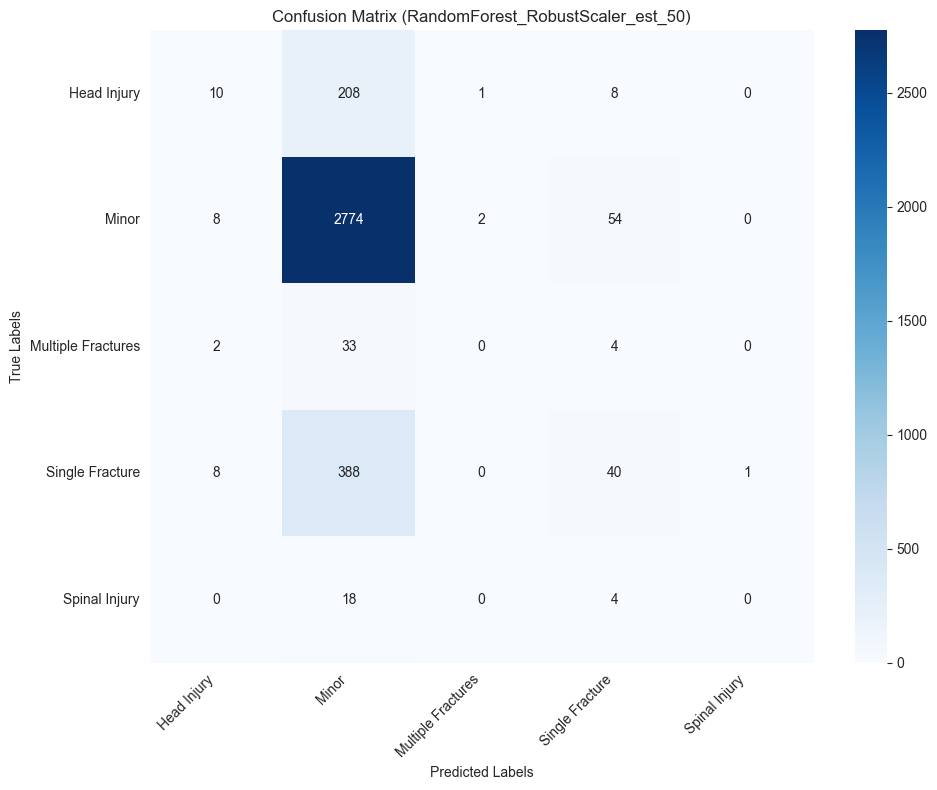

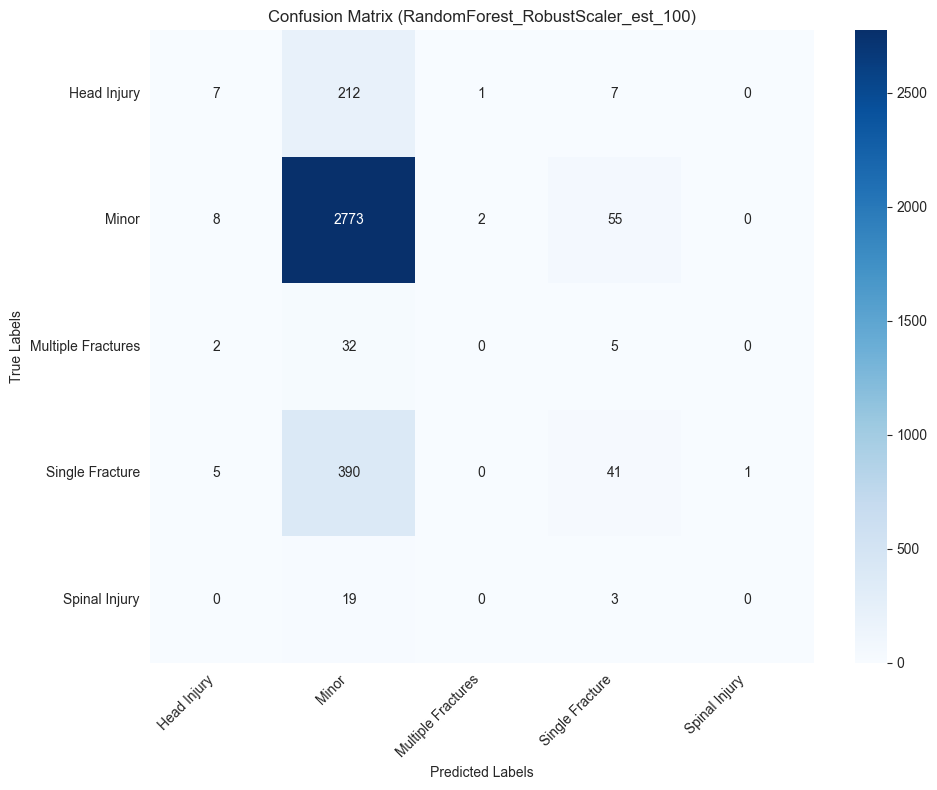

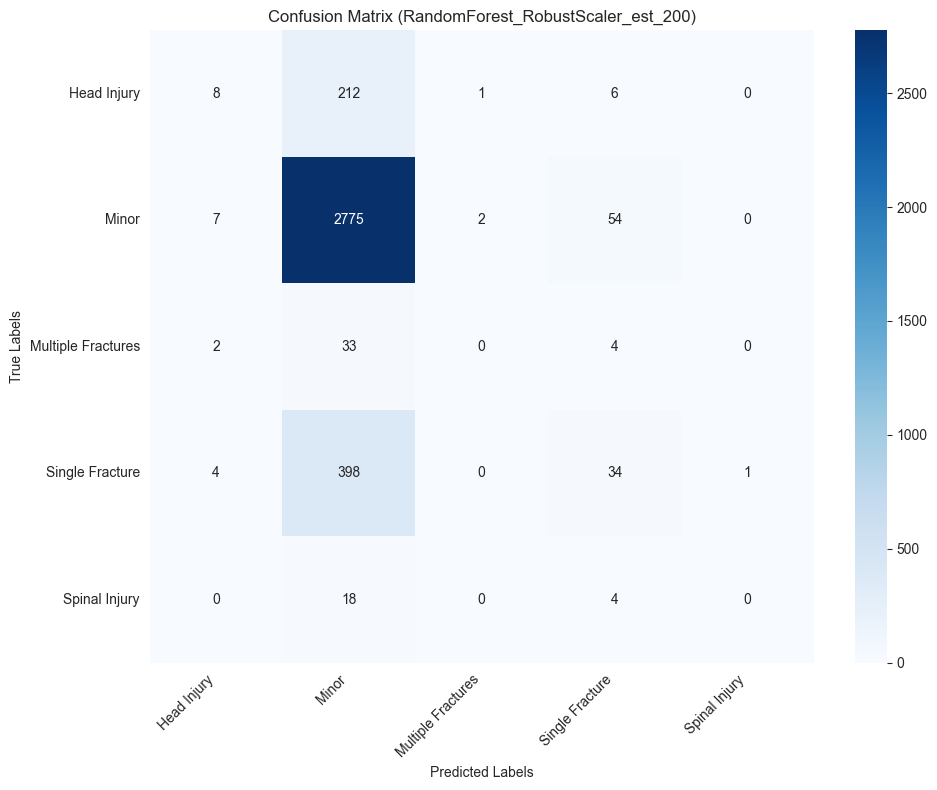

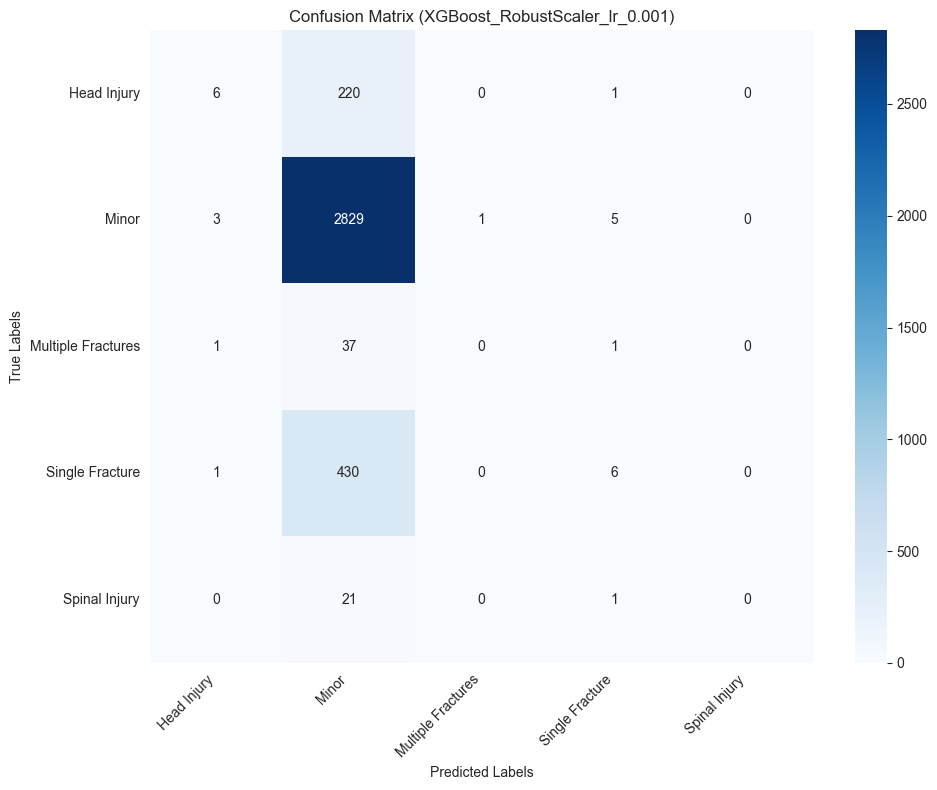

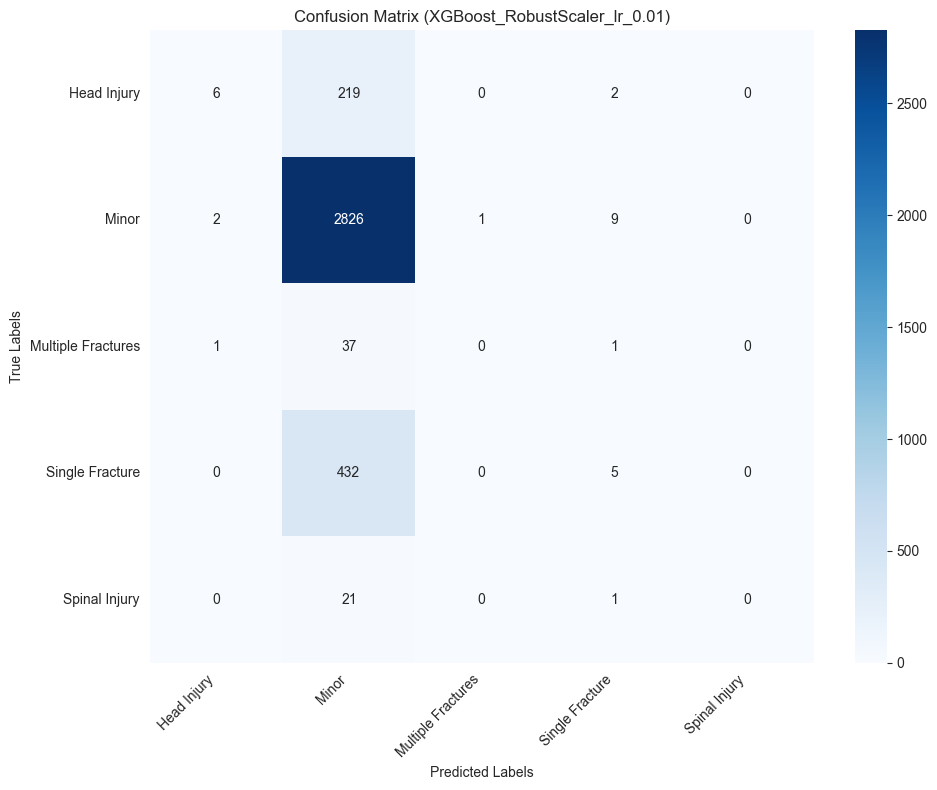

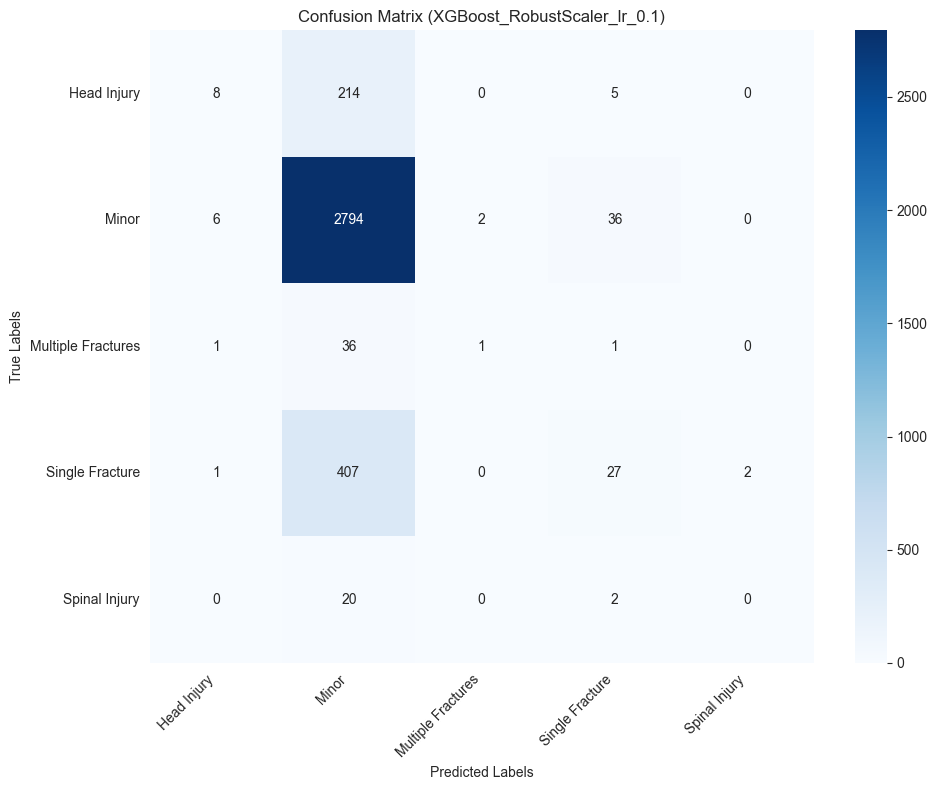

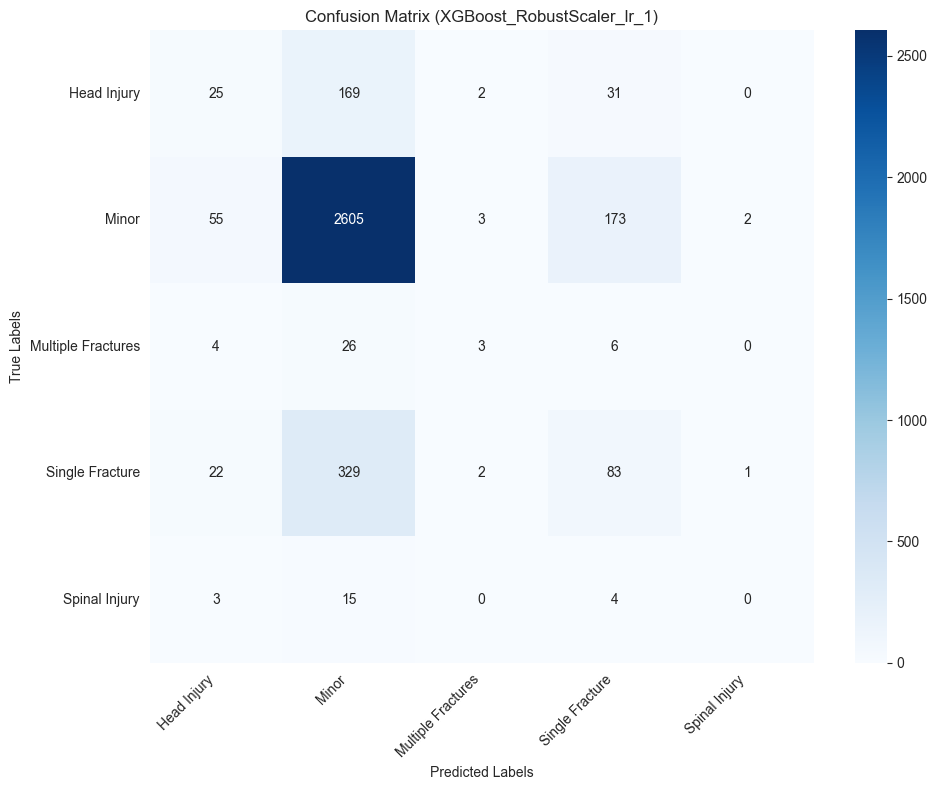

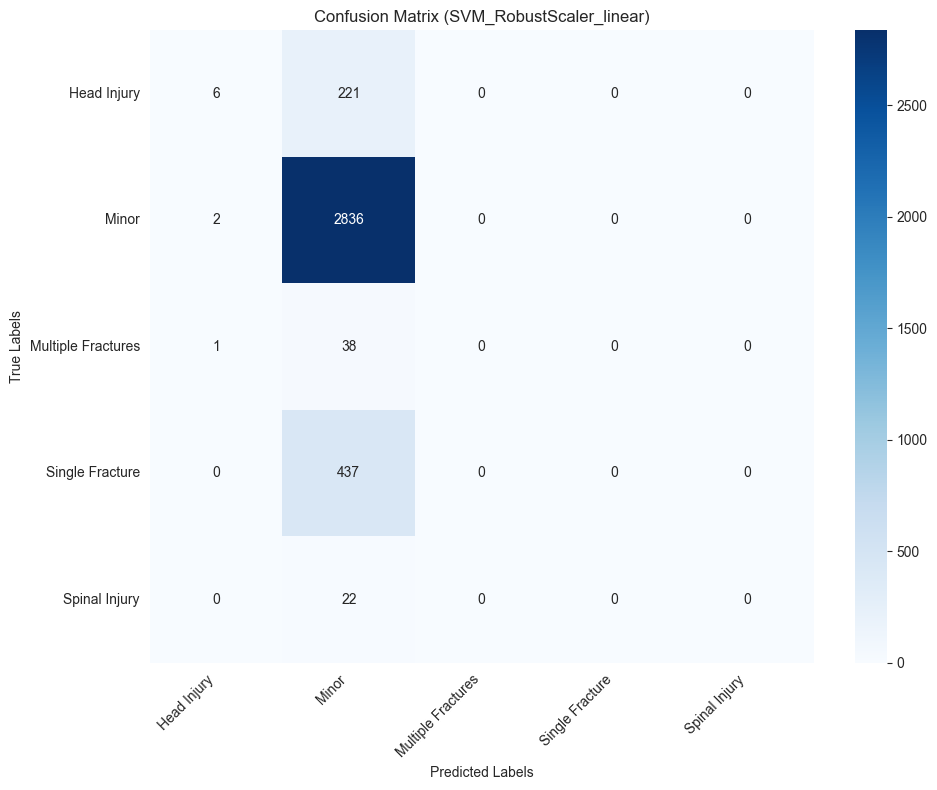

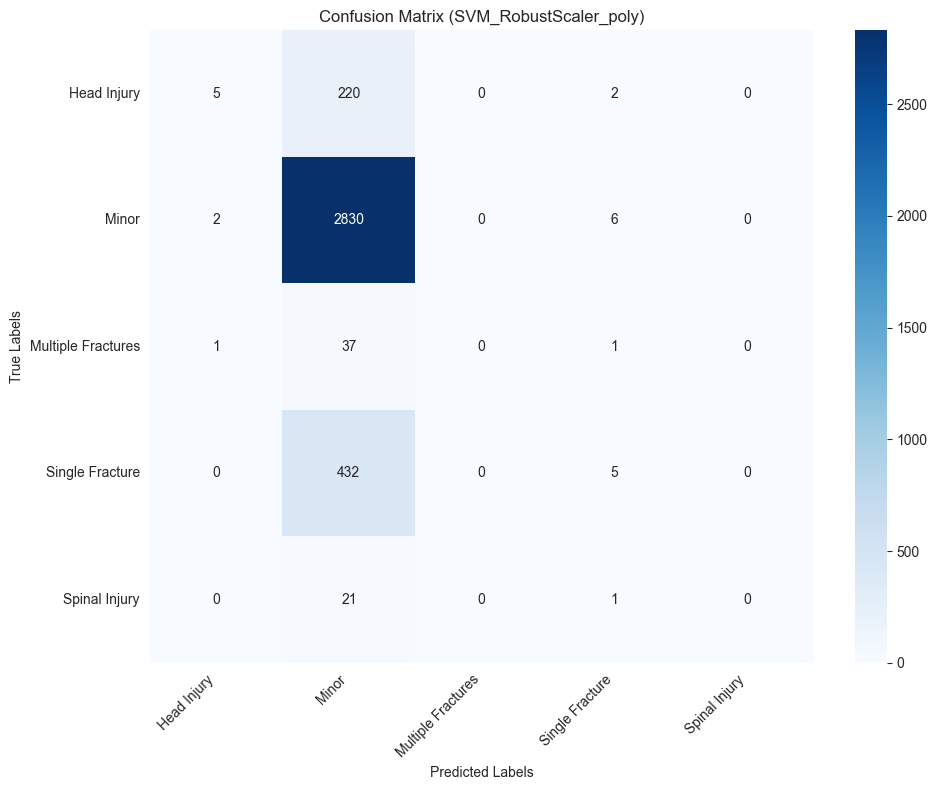

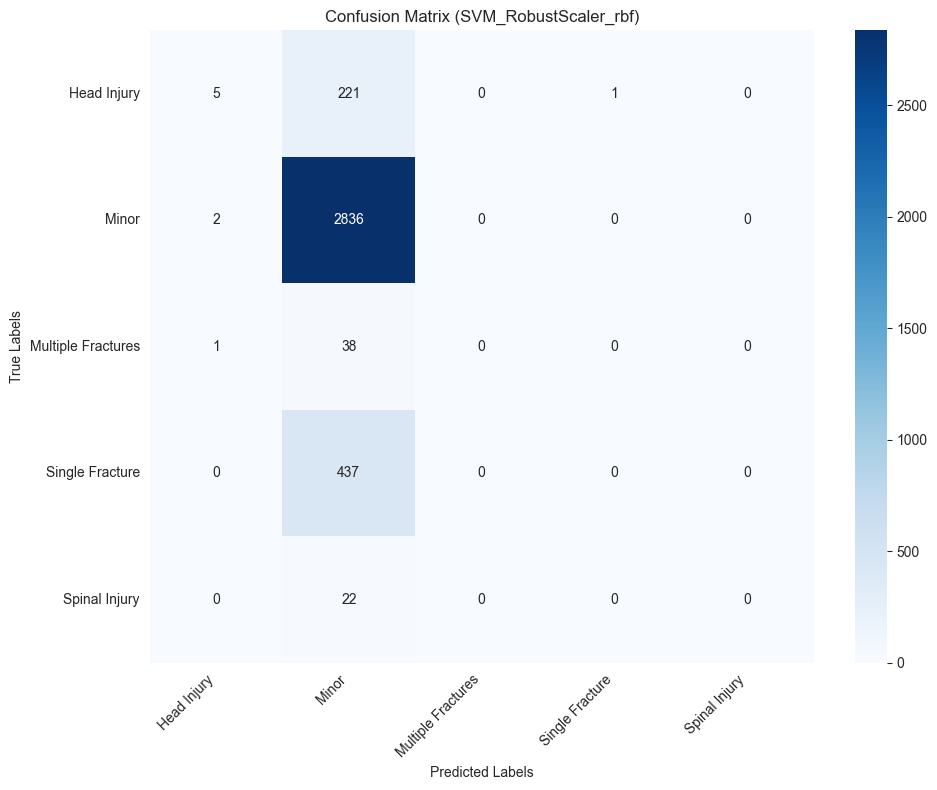

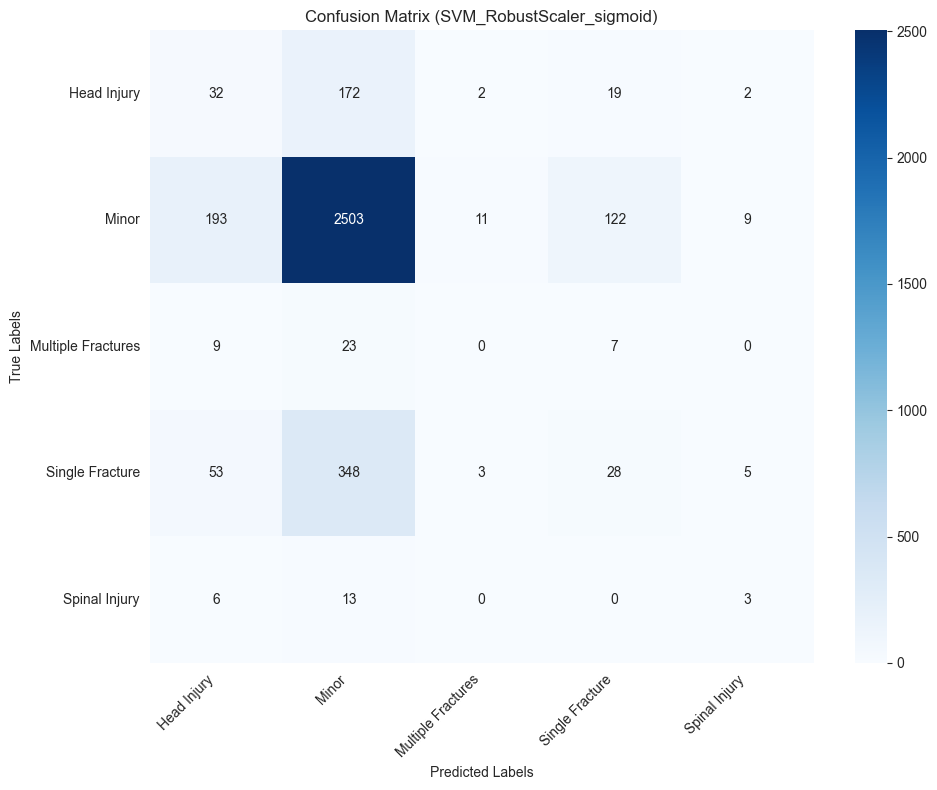

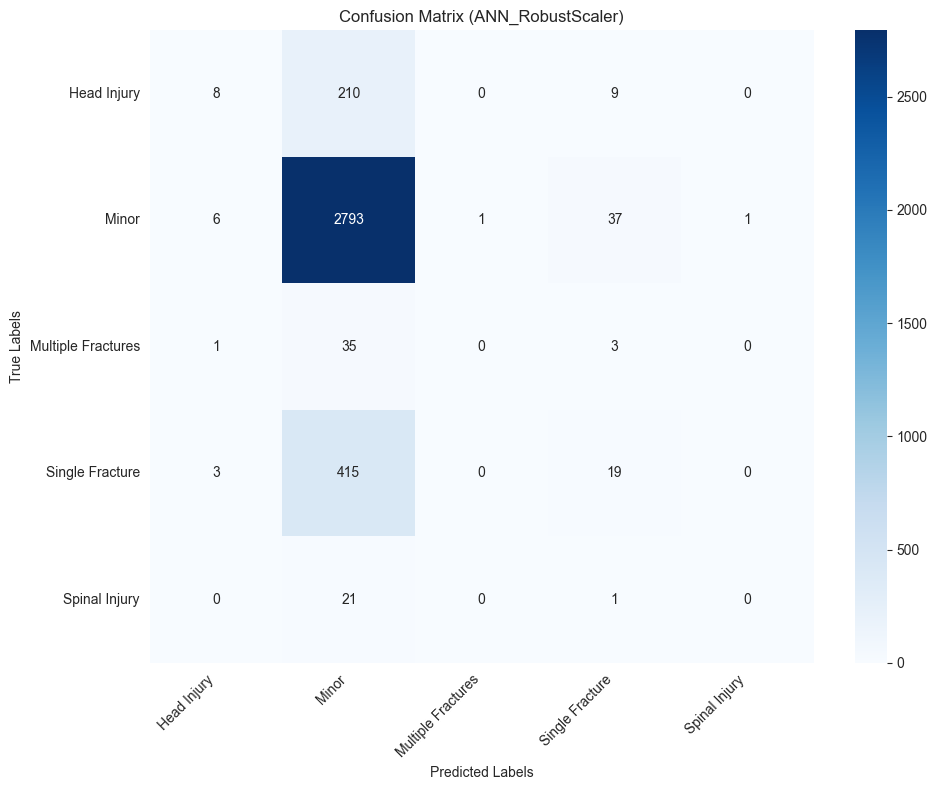

In [52]:
# Update your results dictionary to include ANN results
results = {}

for scaler_name, scaler in scalers.items():
    for model_name, model_list in models.items():
        for i, model in enumerate(model_list):
            if len(model_list) > 1:
                if model_name == 'DecisionTree':
                    config_name = f"{model_name}_{scaler_name}_depth_{dt_depths[i]}"
                elif model_name == 'RandomForest':
                    config_name = f"{model_name}_{scaler_name}_est_{rf_estimators[i]}"
                elif model_name == 'XGBoost':
                    config_name = f"{model_name}_{scaler_name}_lr_{xgb_learning_rates[i]}"
                elif model_name == 'SVM':
                    config_name = f"{model_name}_{scaler_name}_{svm_kernels[i]}"
                elif model_name == 'ANN':
                    config_name = f"{model_name}_{scaler_name}"
            else:
                config_name = f"{model_name}_{scaler_name}"
            
            pipeline = Pipeline([
                ('scaler', scaler),
                ('classifier', model)
            ])
            
            pipeline.fit(X_train, y_train)
            y_pred = pipeline.predict(X_test)
            
            accuracy, report, conf_matrix = evaluate_model(y_test, y_pred, np.unique(y_test))
            
            results[config_name] = {
                'accuracy': accuracy,
                'report': report,
                'conf_matrix': conf_matrix,
                'classes': np.unique(y_test)
            }
            
            plot_confusion_matrix(conf_matrix, np.unique(y_test),
                                f"Confusion Matrix ({config_name})")

#### Plot performance curves

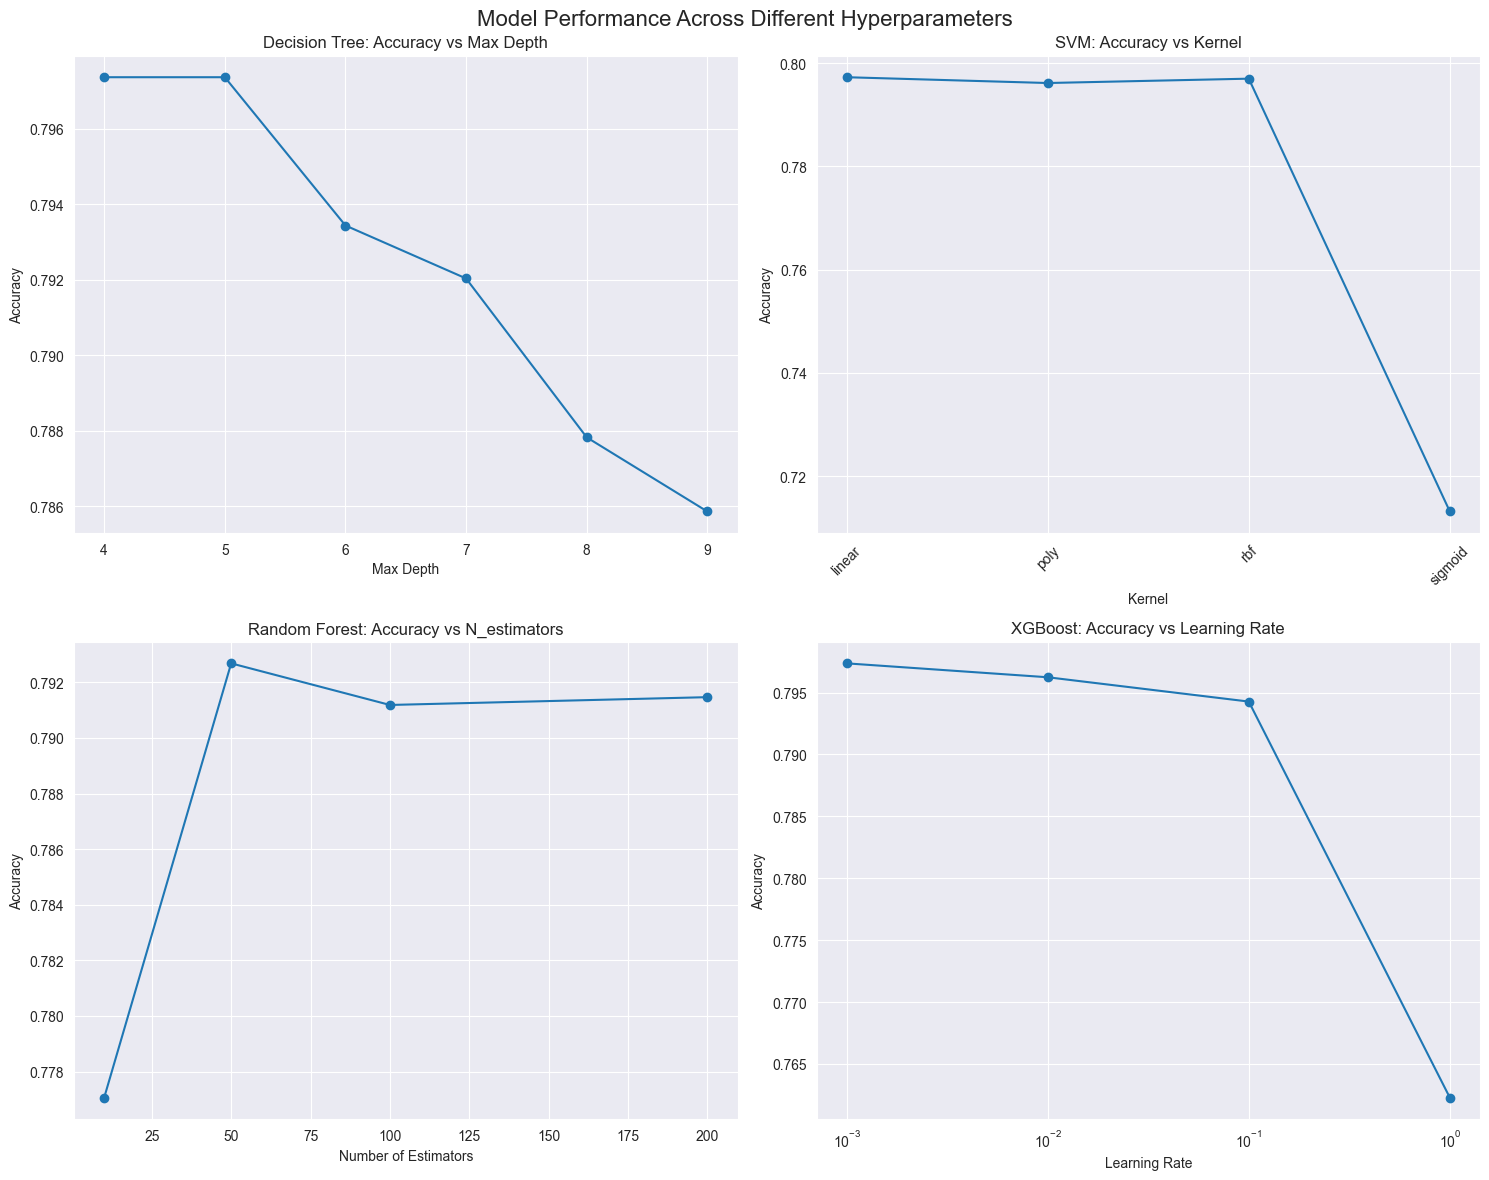

In [53]:
plot_performance_curves(results)

In [54]:
def plot_performance_comparison(results):
    # Create figure with multiple subplots
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))
    
    # Prepare data
    model_accuracies = {}
    model_f1 = {}
    model_precision_recall = {}
    
    for config, metrics in results.items():
        model_name = config.split('_')[0]
        scaler_name = config.split('_')[1]
        
        if model_name not in model_accuracies:
            model_accuracies[model_name] = []
            model_f1[model_name] = []
            model_precision_recall[model_name] = {'precision': [], 'recall': []}
            
        model_accuracies[model_name].append(metrics['accuracy'])
        model_f1[model_name].append(metrics['report']['weighted avg']['f1-score'])
        model_precision_recall[model_name]['precision'].append(metrics['report']['weighted avg']['precision'])
        model_precision_recall[model_name]['recall'].append(metrics['report']['weighted avg']['recall'])
    
    # Calculate statistics
    avg_accuracies = {model: np.mean(accs) for model, accs in model_accuracies.items()}
    std_accuracies = {model: np.std(accs) for model, accs in model_accuracies.items()}
    
    avg_f1 = {model: np.mean(scores) for model, scores in model_f1.items()}
    std_f1 = {model: np.std(scores) for model, scores in model_f1.items()}
    
    avg_precision = {model: np.mean(scores['precision']) for model, scores in model_precision_recall.items()}
    avg_recall = {model: np.mean(scores['recall']) for model, scores in model_precision_recall.items()}
    
    # Plot 1: Accuracy comparison
    models = list(avg_accuracies.keys())
    means = list(avg_accuracies.values())
    stds = list(std_accuracies.values())
    
    bars1 = ax1.bar(models, means, yerr=stds, capsize=5)
    ax1.set_title('Model Accuracy Comparison')
    ax1.set_xlabel('Model')
    ax1.set_ylabel('Accuracy')
    ax1.tick_params(axis='x', rotation=45)
    
    # Add value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom')
    
    # Plot 2: F1-Score comparison
    models = list(avg_f1.keys())
    means = list(avg_f1.values())
    stds = list(std_f1.values())
    
    bars2 = ax2.bar(models, means, yerr=stds, capsize=5)
    ax2.set_title('Model F1-Score Comparison')
    ax2.set_xlabel('Model')
    ax2.set_ylabel('F1-Score')
    ax2.tick_params(axis='x', rotation=45)
    
    # Add value labels on bars
    for bar in bars2:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom')
    
    # Plot 3: Precision-Recall comparison
    x = np.arange(len(models))
    width = 0.35
    
    bars3_1 = ax3.bar(x - width/2, list(avg_precision.values()), width, label='Precision')
    bars3_2 = ax3.bar(x + width/2, list(avg_recall.values()), width, label='Recall')
    
    ax3.set_title('Precision-Recall Comparison')
    ax3.set_xlabel('Model')
    ax3.set_ylabel('Score')
    ax3.set_xticks(x)
    ax3.set_xticklabels(models, rotation=45)
    ax3.legend()
    
    # Add value labels on bars
    for bars in [bars3_1, bars3_2]:
        for bar in bars:
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}',
                    ha='center', va='bottom')
    
    # Adjust layout and display
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\nSummary Statistics:")
    print("-" * 80)
    print(f"{'Model':<15} {'Accuracy':<20} {'F1-Score':<20} {'Precision':<20} {'Recall':<20}")
    print("-" * 80)
    
    for model in models:
        print(f"{model:<15} "
              f"{avg_accuracies[model]:.3f} ± {std_accuracies[model]:.3f}    "
              f"{avg_f1[model]:.3f} ± {std_f1[model]:.3f}    "
              f"{avg_precision[model]:.3f}    "
              f"{avg_recall[model]:.3f}")

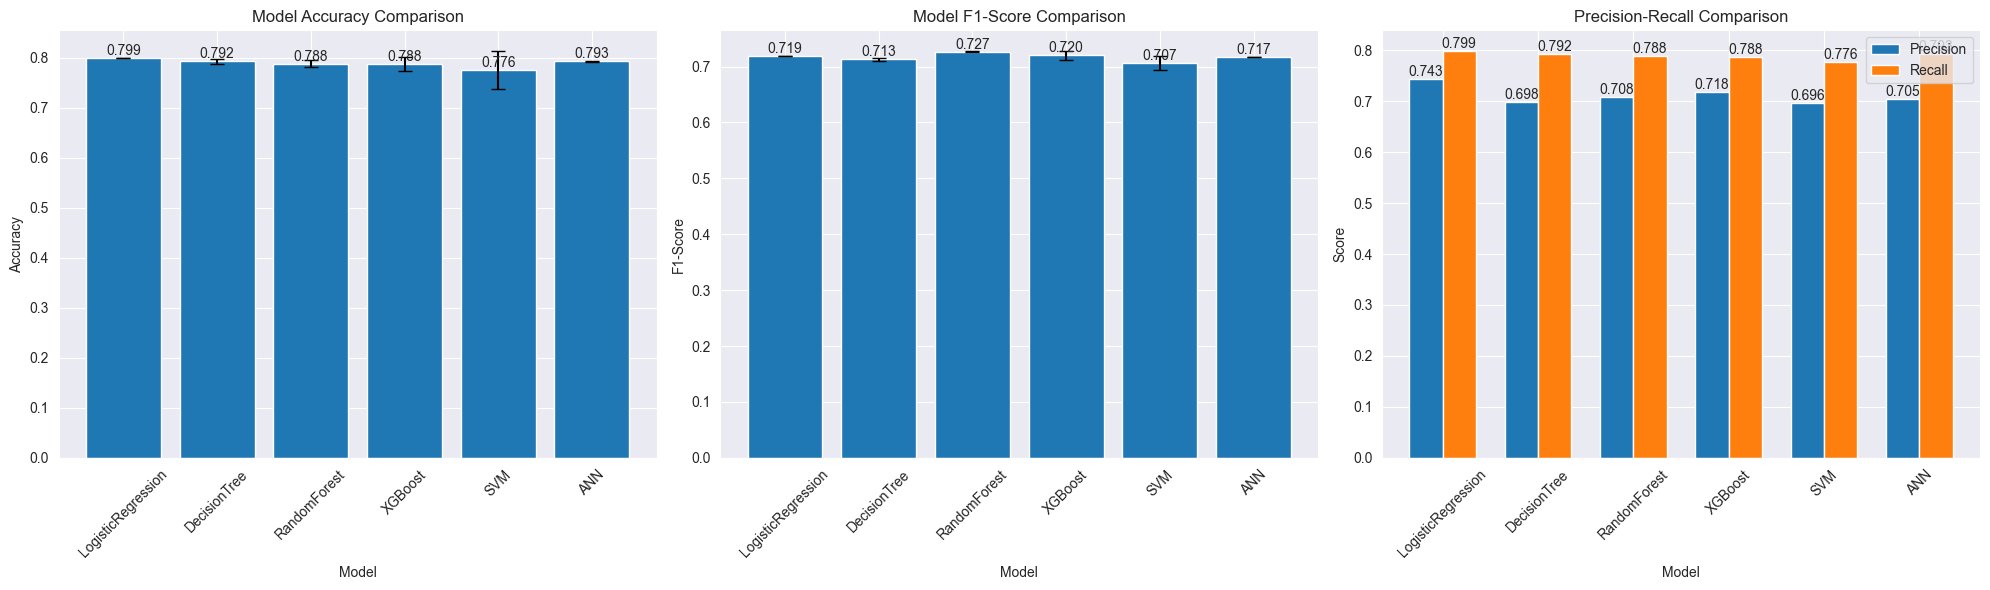


Summary Statistics:
--------------------------------------------------------------------------------
Model           Accuracy             F1-Score             Precision            Recall              
--------------------------------------------------------------------------------
LogisticRegression 0.799 ± 0.000    0.719 ± 0.000    0.743    0.799
DecisionTree    0.792 ± 0.004    0.713 ± 0.002    0.698    0.792
RandomForest    0.788 ± 0.006    0.727 ± 0.002    0.708    0.788
XGBoost         0.788 ± 0.015    0.720 ± 0.008    0.718    0.788
SVM             0.776 ± 0.038    0.707 ± 0.013    0.696    0.776
ANN             0.793 ± 0.001    0.717 ± 0.001    0.705    0.793


In [55]:
# Plot the comparison
plot_performance_comparison(results)

#### Display results summary

In [56]:
 Display final results
print("\nModel Performance Summary (including ANN):")
print("-" * 100)
print(f"{'Model Configuration':<50} {'Accuracy':<10} {'Precision':<10} {'Recall':<10} {'F1-Score':<10}")
print("-" * 100)

for config_name, metrics in results.items():
    report = metrics['report']
    accuracy = metrics['accuracy']
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    print(f"{config_name:<50} {accuracy:.3f}     {precision:.3f}     {recall:.3f}     {f1_score:.3f}")


Model Performance Summary (including ANN):
----------------------------------------------------------------------------------------------------
Model Configuration                                Accuracy   Precision  Recall     F1-Score  
----------------------------------------------------------------------------------------------------
LogisticRegression_StandardScaler                  0.799     0.743     0.799     0.719
DecisionTree_StandardScaler_depth_4                0.797     0.678     0.797     0.710
DecisionTree_StandardScaler_depth_5                0.797     0.727     0.797     0.714
DecisionTree_StandardScaler_depth_6                0.793     0.710     0.793     0.713
DecisionTree_StandardScaler_depth_7                0.792     0.696     0.792     0.710
DecisionTree_StandardScaler_depth_8                0.788     0.689     0.788     0.713
DecisionTree_StandardScaler_depth_9                0.786     0.691     0.786     0.716
RandomForest_StandardScaler_est_10                